# ПЗ-1. Генерация текста с использованием RNN/LSTM

В этой практической работе рассмотрим полный пайплайн генерации текста с помощью нейронных сетей.

На примере новостных текстов последовательно пройдем основные этапы работы с языковой моделью:

* подготовка и очистка текстового корпуса;
* токенизация текста разными способами;
* формирование обучающих последовательностей;
* создание моделей `Dense`, `RNN` и `LSTM`;
* обучение моделей и отслеживание экспериментов с помощью MLflow;
* оценка качества по `loss` и `perplexity`;
* генерация продолжения текста по заданному prompt;
* сравнение результатов разных токенизаторов и архитектур.

Главная цель практики - познакомиться не с отдельной моделью, а с **полным циклом построения эксперимента по генерации текста**: от исходного корпуса до обучения, оценки и анализа результатов.


**Выполнил:** Бабушкин Михаил Вадимович, ЕТ-228, 2026.

Выполнены задания 1–4: базовые 18 экспериментов, 9 дополнительных моделей, графики и сравнение greedy-генерации на трёх одинаковых примерах. Базовые результаты сохранены; расширенная серия записана отдельно в MLflow.

## 0. Установка зависимостей и импорты

In [1]:
#!pip install -q datasets mlflow
# В локальном окружении: python -m pip install -r requirements.txt


In [1]:
import os
import re
import gc
import math
import time
import json
import pickle
import random
import hashlib
import platform
from pathlib import Path
from collections import Counter
from itertools import islice

PRACTICE_DIR = Path.cwd().resolve()
if not (PRACTICE_DIR / "01-lstm.ipynb").is_file():
    raise RuntimeError("Запускайте ядро из каталога этой практической работы")
CACHE_DIR = PRACTICE_DIR / ".cache"
CACHE_DIR.mkdir(exist_ok=True)
os.environ["HF_HOME"] = str(CACHE_DIR / "huggingface")
os.environ["MPLCONFIGDIR"] = str(CACHE_DIR / "matplotlib")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import mlflow
from mlflow.tracking import MlflowClient
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder
from tokenizers.trainers import BpeTrainer
from datasets import load_dataset
from huggingface_hub import HfApi
from razdel import tokenize as razdel_tokenize
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cpu")
print("Python:", platform.python_version(), "PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())


/Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/19 12:54:07 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/mikhail/Developer/2026-autumn/NNTSM-2026/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Python: 3.12.10 PyTorch: 2.14.1
MPS available: True


### Настройка MLflow

База экспериментов находится в `.cache/mlflow.db`, артефакты — в `.cache/mlruns`.
Для переноса результатов нужны оба объекта. Пробная эпоха записывается в отдельный эксперимент.
В основной серии сохраняются параметры, версии окружения, метрики, время, лучшие веса и токенизатор.

In [2]:
mlflow.set_tracking_uri(f"sqlite:///{CACHE_DIR / 'mlflow.db'}")
EXPERIMENT_NAME = "pz1_text_generation"
PROBE_EXPERIMENT_NAME = "pz1_text_generation_probe"
client = MlflowClient()
for name in [EXPERIMENT_NAME, PROBE_EXPERIMENT_NAME]:
    if client.get_experiment_by_name(name) is None:
        client.create_experiment(name, artifact_location=(CACHE_DIR / "mlruns" / name).as_uri())
mlflow.set_experiment(EXPERIMENT_NAME)
EXPERIMENT_ID = client.get_experiment_by_name(EXPERIMENT_NAME).experiment_id


## 1. Подготовка данных

В работе используется набор данных `IlyaGusev/gazeta`, содержащий русскоязычные новостные статьи с сайта «Газета.Ru». 
Изначально набор данных предназначен для задачи автоматического реферирования: для каждой новости представлены полный текст статьи и ее краткое изложение.

Для нашей задачи важна именно **полная версия новостных статей**. Эти тексты образуют корпус, на котором модель будет изучать закономерности русского языка и впоследствии генерировать новые последовательности текста.

Корпус состоит из новостей на различные темы и содержит большое количество естественных примеров русского языка. Благодаря этому модель может обучаться на реальных словах, их сочетаниях, предложениях и характерных для новостных текстов языковых конструкциях.

В работе количество используемых статей ограничивается параметром:

```python
RAW_ARTICLES_LIMIT = 10000
```
Если вычислительные ресурсы позволяют, рекомендуется увеличить это значение. Использование большего количества статей дает модели больше разнообразных примеров для обучения и может положительно повлиять на качество и разнообразие генерируемого текста.

In [3]:
RAW_ARTICLES_LIMIT = 1000
DATASET_NAME = "IlyaGusev/gazeta"
DATA_CACHE = CACHE_DIR / "gazeta_first_1000.json"
if DATA_CACHE.exists():
    corpus = json.loads(DATA_CACHE.read_text(encoding="utf-8"))
else:
    revision = HfApi().dataset_info(DATASET_NAME).sha
    ds = load_dataset(DATASET_NAME, revision=revision, split="train", streaming=True)
    records = [{"id": str(row.get("id", i)), "text": row["text"]}
               for i, row in enumerate(islice(ds, RAW_ARTICLES_LIMIT))]
    corpus = {"dataset": DATASET_NAME, "revision": revision, "split": "train", "records": records}
    DATA_CACHE.write_text(json.dumps(corpus, ensure_ascii=False), encoding="utf-8")
assert corpus["dataset"] == DATASET_NAME and len(corpus["records"]) == RAW_ARTICLES_LIMIT
assert all(isinstance(r["text"], str) and r["text"].strip() for r in corpus["records"])
DATA_SHA256 = hashlib.sha256(DATA_CACHE.read_bytes()).hexdigest()
texts = [r["text"] for r in corpus["records"]]
print("Источник:", corpus["dataset"], "revision:", corpus["revision"])
print("SHA-256:", DATA_SHA256)
print(f"Загружено статей: {len(texts)}")
print(texts[0][:300])


Источник: IlyaGusev/gazeta revision: c4d8e46f79e17c4a864a320e6773436dc28fddd8
SHA-256: b1ebcdd88db3f13fda6c837e3ab17459b65dc8bf636f64756c2efe00f25c9f46
Загружено статей: 1000
Сегодня транспортный налог начисляется в зависимости от мощности автомобиля, причем цена для «сильных» машин выше, чем для малолитражек. Также ставку налога могут корректировать региональные власти: согласно Налоговому кодексу, базовый тариф, установленный правительством, может быть уменьшен в пять 


## Очистка текстов

Перед обучением модели исходные статьи необходимо привести к более однородному виду. 
В текстах могут встречаться HTML-теги, специальные HTML-последовательности, лишние пробелы и переносы строк. 
Кроме того, для упрощения последующей обработки из текста удаляются знаки пунктуации, чтобы они не становились дополнительными токенами и не увеличивали сложность задачи для относительно простых моделей.
Для этого используется функция `clean_text`

In [4]:
def clean_text(text: str) -> str:
    """
    Очищает текст новостной статьи от HTML-разметки,
    лишних пробелов и знаков пунктуации.

    Args:
        text: Исходный текст статьи.

    Returns:
        Очищенный текст.
    """
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"&\w+;", " ", text)
    text = re.sub(r"[\r\t]+", " ", text)
    text = re.sub(r"\n{2,}", "\n", text)
    text = re.sub(r" {2,}", " ", text)
    for tok in ', ! ? : ; — – ( ) [ ] { } « » "'.split():
        text = text.replace(tok, '')
    return text.strip()


texts = [clean_text(t) for t in texts]

## Разделение корпуса

После очистки корпуса разделяем статьи на обучающую, валидационную и тестовую выборки.

Важно, что в данном случае мы делим данные **по документам, а не по отдельным предложениям**. 
Одна новостная статья представляет собой связный текст и содержит повторяющиеся слова, темы и языковые конструкции. 
Если разделять предложения случайным образом, предложения из одной и той же статьи могут попасть одновременно в `train`, `val` и `test`. 
В результате модель при проверке может встретить знакомые ей фрагменты текста, и оценка качества будет менее показательной.


В текущем корпусе есть точные дубликаты. Одинаковые очищенные тексты группируются до разбиения: группы размещаются целиком, сохраняя размеры 500/250/250. Порядок групп определяется seed 42; группы дубликатов размещаются перед одиночными статьями.

In [5]:
# Поэтому сначала перемешиваем целые статьи
indices = list(range(len(texts)))
random.Random(SEED).shuffle(indices)
# Одинаковые очищенные тексты остаются в одной выборке, чтобы исключить утечку.
groups = {}
for idx in indices:
    groups.setdefault(texts[idx], []).append(idx)
split_indices = [[], [], []]
capacities = [500, 250, 250]
for group in sorted(groups.values(), key=len, reverse=True):
    target = next(i for i, capacity in enumerate(capacities)
                  if len(split_indices[i]) + len(group) <= capacity)
    split_indices[target].extend(group)
indices = [idx for split in split_indices for idx in split]
texts = [texts[i] for i in indices]
print("Повторяющихся статей:", len(texts) - len(groups))

#А затем распределяем документы между тремя выборками
n = len(texts)
n_train = int(n * 0.5)
n_val = int(n * 0.25)
train_docs = texts[:n_train]
val_docs = texts[n_train:n_train + n_val]
test_docs = texts[n_train + n_val:]
train_ids = set(indices[:n_train])
val_ids = set(indices[n_train:n_train + n_val])
test_ids = set(indices[n_train + n_val:])
assert not (train_ids & val_ids or train_ids & test_ids or val_ids & test_ids)
assert not (set(train_docs) & set(val_docs) or set(train_docs) & set(test_docs) or set(val_docs) & set(test_docs))
assert (len(train_docs), len(val_docs), len(test_docs)) == (500, 250, 250)
assert all(doc.strip() for doc in texts)
print(f"train={len(train_docs)}  val={len(val_docs)}  test={len(test_docs)}")


Повторяющихся статей: 35
train=500  val=250  test=250


## 2. Токенизация

Перед подачей текста в модель его необходимо преобразовать в последовательность токенов.
В работе мы сравним несколько различных подходов к токенизации и посмотрим, как выбранный токенизатор влияет на размер словаря, длину последовательностей и последующее обучение модели.
Чтобы разные токенизаторы имели единый интерфейс и их было удобно использовать в одном коде, введем общий базовый класс `BaseTokenizer`
Базовый класс задает общий набор операций, которые должен поддерживать каждый используемый токенизатор.


In [6]:
class BaseTokenizer:
    """Базовый интерфейс токенизатора для работы с текстовыми данными."""

    pad_id = 0

    def encode(self, text: str) -> list[int]:
        """Преобразует текст в последовательность идентификаторов токенов.

        Args:
            text: Исходный текст для токенизации.

        Returns:
            Последовательность идентификаторов токенов.

        """
        raise NotImplementedError

    def decode(self, ids: list[int]) -> str:
        """Восстанавливает текст из последовательности идентификаторов.

        Args:
            ids: Последовательность идентификаторов токенов.

        Returns:
            Восстановленный текст.

        """
        raise NotImplementedError

    @property
    def vocab_size(self) -> int:
        """Возвращает размер словаря токенизатора.

        Returns:
            Количество токенов в словаре.
        """
        raise NotImplementedError

    def get_token_count(self, text: str) -> int:
        """Возвращает количество токенов в переданном тексте.

        Args:
            text: Исходный текст.

        Returns:
            Количество токенов.
        """
        return len(self.encode(text))

## Символьный токенизатор

Первым рассмотрим самый простой вариант токенизации: посимвольный `CharTokenizer`.
В этом подходе каждый отдельный символ текста рассматривается как самостоятельный токен.
Сначала на основе всех текстов корпуса формируется множество уникальных символов. 
Затем каждому символу сопоставляется свой числовой идентификатор.


### Специальные токены
Специальные токены - это служебные элементы словаря, которые не являются обычными символами текста.
Они нужны, чтобы передавать модели дополнительную информацию о структуре последовательности: где находятся пустые позиции, какой символ неизвестен токенизатору и где заканчивается текст.
В данном токенизаторе используются три специальных токена: `<pad>`, `<unk>` и `<eos>`.
`<pad>` используется для выравнивания последовательностей разной длины.
Например, если одна последовательность содержит 5 токенов, а другая 8, их можно привести к общей длине:
```text
а б в г д <pad> <pad> <pad>
а б в г д е ж з
```
`<unk>` - неизвестный токен
Он используется, если во входном тексте встречается символ или слово, которого нет в словаре токенизатора.
Такой символ заменяется на <unk>, чтобы модель могла продолжить обработку последовательности.

`<eos>` конец последовательности
<eos> означает end of sequence, он позволяет явно обозначить границу текста.
при генерации такой токен может использоваться как сигнал о том, что последовательность следует завершить.

In [7]:
class CharTokenizer(BaseTokenizer):
    def __init__(self, docs):
        chars = sorted(set("".join(docs)))
        vocab = ["<pad>", "<unk>", "<eos>"] + chars
        self.stoi = {ch: i for i, ch in enumerate(vocab)}
        self.itos = {i: ch for ch, i in self.stoi.items()}
        self.pad_id = self.stoi["<pad>"]
        self.unk_id = self.stoi["<unk>"]
        self.eos_id = self.stoi["<eos>"]

    @property
    def vocab_size(self):
        return len(self.stoi)

    def encode(self, text):
        return [self.stoi.get(ch, self.unk_id) for ch in text]

    def decode(self, ids):
        return "".join(self.itos.get(i, "") for i in ids)

# Задание 1
Первое задание: по аналогии с `CharTokenizer` реализовать токенизатор `WordTokenizer`.

В отличие от `CharTokenizer`, где каждый символ текста является отдельным токеном, `WordTokenizer` должен рассматривать слова как токены.

Необходимо самостоятельно реализовать класс `WordTokenizer`, сохранив тот же интерфейс, что и у базового токенизатора.

При этом необходимо учитывать ограничение на размер словаря . 
Если в корпусе встречается слишком много разных слов, в словарь следует включать только наиболее часто встречающиеся слова.
Остальные слова при токенизации должны рассматриваться как неизвестные и заменяться на `<unk>`.


In [8]:
def word_tokenize(text):
    return [tok.text.lower() for tok in razdel_tokenize(text)]


class WordTokenizer(BaseTokenizer):
    def __init__(self, docs, max_size=20000):
        if max_size < 3:
            raise ValueError("max_size должен вмещать три специальных токена")
        counts = Counter(word for doc in docs for word in word_tokenize(doc))
        vocab = ["<pad>", "<unk>", "<eos>"]
        vocab += [word for word, _ in counts.most_common(max_size - len(vocab))]
        self.stoi = {word: i for i, word in enumerate(vocab)}
        self.itos = {i: word for word, i in self.stoi.items()}
        self.pad_id = self.stoi["<pad>"]
        self.unk_id = self.stoi["<unk>"]
        self.eos_id = self.stoi["<eos>"]

    @property
    def vocab_size(self):
        return len(self.stoi)

    def encode(self, text):
        return [self.stoi.get(word, self.unk_id) for word in word_tokenize(text)]

    def decode(self, ids):
        return " ".join(self.itos.get(int(i), "<unk>") for i in ids)


Следующий вариант - BPE (Byte Pair Encoding). 

В отличие от CharTokenizer и WordTokenizer, BPE разбивает текст на части слов, что позволяет работать и с часто встречающимися словами, и с редкими словами через их известные части

```
машина → маш + ина
машинка → маш + инка

работает → работ + ает
работал → работ + ал ```

In [9]:
class BPETokenizer(BaseTokenizer):
    def __init__(self, docs, vocab_size=16000):
        self.tokenizer = Tokenizer(BPE(unk_token="<unk>"))
        self.tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
        self.tokenizer.decoder = ByteLevelDecoder()


        trainer = BpeTrainer(vocab_size=vocab_size, special_tokens=["<pad>", "<unk>", "<eos>", ])
        self.tokenizer.train_from_iterator(docs, trainer=trainer)

        self.stoi = self.tokenizer.get_vocab()
        self.itos = {idx: token for token, idx in self.stoi.items()}

        self.pad_id = self.stoi["<pad>"]
        self.unk_id = self.stoi["<unk>"]
        self.eos_id = self.stoi["<eos>"]

    @property
    def vocab_size(self):
        return self.tokenizer.get_vocab_size()

    def encode(self, text):
        return self.tokenizer.encode(text).ids

    def decode(self, ids):
        return self.tokenizer.decode(ids)

    def tokenize(self, text):
        return self.tokenizer.encode(text).tokens

In [11]:
char_tokenizer = CharTokenizer(train_docs)
word_tokenizer = WordTokenizer(train_docs, max_size=50000)
bre_tokenizer = BPETokenizer(train_docs, vocab_size=8000)
TOKENIZER = {'bre': bre_tokenizer, 'char': char_tokenizer, 'word': word_tokenizer}


Сравним токенизаторы по размеру словаря и доле неизвестных токенов `<unk>`


In [12]:
print("Char vocab size:", char_tokenizer.vocab_size)
print("Word vocab size:", word_tokenizer.vocab_size)


def unk_rate(text, tokenizer):
    ids = tokenizer.encode(text)
    return sum(i == tokenizer.unk_id for i in ids) / len(ids)


print(f"[bre] Доля <unk> в train: {unk_rate(' '.join(train_docs[:1000]), bre_tokenizer):.1%}")
print(f"[word] Доля <unk> в train: {unk_rate(' '.join(train_docs[:1000]), word_tokenizer):.1%}")


Char vocab size: 148
Word vocab size: 49005
[bre] Доля <unk> в train: 0.0%


[word] Доля <unk> в train: 0.0%


Размер словаря и доля `<unk>` вычисляются выше для текущих 500 обучающих статей. Значения зависят от корпуса и ограничения словаря.

Посмотрим на распределение слов в обучающей выборке.

In [13]:
from razdel import tokenize as razdel_tokenize


def word_tokenize(text):
    return [tok.text.lower() for tok in razdel_tokenize(text)]

print("vocab size:", word_tokenizer.vocab_size)

counter = Counter()

for doc in train_docs:
    counter.update(word_tokenize(doc))

print("unique words:", len(counter))

print("\nMost common:")
for word, count in counter.most_common(5):
    print(repr(word), count)

print("\nRare:")
print(sum(c == 1 for c in counter.values()))
print(sum(c <= 5 for c in counter.values()))

vocab size: 49005


unique words: 49002

Most common:
'.' 17737
'в' 12061
'и' 7151
'на' 5275
'не' 4074

Rare:
25387
41946


Частотное распределение выше относится к текущей обучающей выборке. Редкие слова занимают места в словаре, но дают мало обучающих примеров.

In [14]:
print("Примеры редких слов:")

rare_words = [word for word, count in counter.items() if count == 1]

for word in rare_words[100:110]:
    print(repr(word))

Примеры редких слов:
'мексика'
'рывка'
'игрушечным'
'ковбоям'
'sony'
'мучилась'
'переводом'
'grown'
'ups'
'вариантом'


Проблема не только в том, что это редкие слова. Среди них могут быть важные для конкретного контекста слова: фамилии, имена, названия организаций, географические названия и другие детали.
При ограниченном словаре такие слова заменяются на `<unk>`, из-за чего модель теряет часть информации о содержании текста. Для генерации это может приводить к потере конкретики и ухудшению связности текста.

## Задание 2: подготовка данных

Языковая модель обучается предсказывать **следующий токен по предыдущим токенам**. При этом предсказание выполняется на каждом шаге последовательности.

Например, для текста:

```text
я люблю читать книги
```

обучающая пара выглядит так:

```text
Input:  я      люблю   читать
Target: люблю  читать  книги
```

Таким образом, модель учится:

* по `я` предсказывать `люблю`;
* по `я люблю` предсказывать `читать`;
* по `я люблю читать` предсказывать `книги`.

Для создания большого количества таких примеров используется **скользящее окно**.

### Задание

Необходимо реализовать класс `SlidingWindowDataset`, который:

* преобразует документы в последовательности токенов;
* формирует последовательности фиксированной длины `seq_len`;
* создает `input` и `target`, сдвигая `target` на один токен относительно `input`;
* использует параметр `stride` для управления шагом скользящего окна;
* добавляет разделитель между статьями.


In [10]:
class SlidingWindowDataset(Dataset):
    """Формирует обучающие пары из текста с помощью скользящего окна.

    Args:
        docs: Список текстовых документов.
        tokenizer: Токенизатор для преобразования текста в идентификаторы.
        seq_len: Длина входной последовательности.
        stride: Шаг перемещения окна. Если не задан, равен seq_len.

    Returns:
        Пара тензоров (input, target), где target содержит
        последовательность токенов, сдвинутую на один шаг.
    """

    def __init__(self, docs, tokenizer, seq_len, stride=None):
        if seq_len <= 0 or (stride is not None and stride <= 0):
            raise ValueError("seq_len и stride должны быть положительными")
        self.seq_len = seq_len
        self.stride = seq_len if stride is None else stride
        tokens = []
        for doc in docs:
            tokens.extend(tokenizer.encode(doc))
            tokens.append(tokenizer.eos_id)
        self.tokens = torch.tensor(tokens, dtype=torch.long)

    def __len__(self):
        """Возвращает количество доступных обучающих примеров.

       Returns:
           Количество последовательностей."""
        return max(0, (len(self.tokens) - self.seq_len - 1) // self.stride + 1)

    def __getitem__(self, idx):
        """Возвращает одну пару входной и целевой последовательностей.

        Args:
            idx: Индекс обучающего примера.

        Returns:
            Кортеж из входной последовательности и целевой последовательности.
        """
        if idx < 0 or idx >= len(self):
            raise IndexError(idx)
        start = idx * self.stride
        return (self.tokens[start:start + self.seq_len],
                self.tokens[start + 1:start + self.seq_len + 1])

def make_loaders(train_docs, val_docs, test_docs, tokenizer, seq_len, batch_size=64, stride=None):
    """Создает DataLoader для обучающей, валидационной и тестовой выборок.

    Args:
        train_docs: Обучающие документы.
        val_docs: Валидационные документы.
        test_docs: Тестовые документы.
        tokenizer: Токенизатор.
        seq_len: Длина входной последовательности.
        batch_size: Размер батча.
        stride: Шаг скользящего окна.

    Returns:
        Кортеж из трех DataLoader: для обучения, валидации и тестирования.
    """
    train_ds = SlidingWindowDataset(train_docs, tokenizer, seq_len, stride)
    val_ds = SlidingWindowDataset(val_docs, tokenizer, seq_len, stride)
    test_ds = SlidingWindowDataset(test_docs, tokenizer, seq_len, stride)
    if any(len(ds) == 0 for ds in (train_ds, val_ds, test_ds)):
        raise ValueError("Каждая выборка должна содержать хотя бы одно полное окно")
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, drop_last=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, drop_last=False)
    return train_loader, val_loader, test_loader

### Самопроверки реализованных классов

In [16]:

small = WordTokenizer(["Кот кот дом"], max_size=5)
assert small.vocab_size == 5 and small.encode("КОТ") == small.encode("кот")
assert small.encode("неизвестное") == [small.unk_id]
assert small.decode(small.encode("Кот дом")) == "кот дом"
assert small.encode("") == [] and small.decode([]) == ""
assert WordTokenizer([], max_size=3).vocab_size == 3
assert CharTokenizer(["аб"]).encode("в") == [1]
for bad_size in (0, 2):
    try:
        WordTokenizer([], max_size=bad_size)
    except ValueError:
        pass
    else:
        raise AssertionError("Недопустимый max_size принят")
tok = CharTokenizer(["абвг"])
ds_check = SlidingWindowDataset(["аб", "вг"], tok, seq_len=2, stride=1)
expected = tok.encode("аб") + [tok.eos_id] + tok.encode("вг") + [tok.eos_id]
assert ds_check.tokens.tolist() == expected and len(ds_check) == 4
for i in range(len(ds_check)):
    x, y = ds_check[i]
    assert x.dtype == y.dtype == torch.long
    assert x.tolist() == expected[i:i + 2] and y.tolist() == expected[i + 1:i + 3]
assert len(SlidingWindowDataset(["аб", "вг"], tok, 2)) == 2
assert len(SlidingWindowDataset(["а"], tok, 2)) == 0
assert len(SlidingWindowDataset([], tok, 2)) == 0
assert len(SlidingWindowDataset(["аб"], tok, 2)) == 1
for length, stride in [(0, None), (2, 0), (2, -1)]:
    try:
        SlidingWindowDataset(["аб"], tok, length, stride)
    except ValueError:
        pass
    else:
        raise AssertionError("Недопустимый размер окна принят")
try:
    make_loaders([], ["аб"], ["аб"], tok, 2)
except ValueError:
    pass
else:
    raise AssertionError("Пустая обучающая выборка принята")
assert set(char_tokenizer.stoi) - {"<pad>", "<unk>", "<eos>"} == set("".join(train_docs))
assert set(word_tokenizer.stoi) - {"<pad>", "<unk>", "<eos>"} <= set(counter)
assert sum(1 for _ in corpus["records"]) == len(train_ids | val_ids | test_ids)
print("Самопроверки токенизаторов, окон и разбиения: OK")


Самопроверки токенизаторов, окон и разбиения: OK


## Архитектуры языковых моделей

В следующих ячейках задается несколько моделей, которые будут решать одну и ту же задачу предсказания следующего токена. 

### Общая архитектура

`BaseLanguageModel` содержит общую часть всех моделей.

Сначала `Embedding` преобразует идентификаторы токенов в векторы. Затем в `encode_step` обрабатывается вектор каждого токена выбранной моделью: `Dense`, `RNN` или `LSTM`, и формируется его скрытое представление.

Слой `Linear` преобразует скрытые состояния в `logits` - оценки для всех токенов словаря. По ним модель определяет, какой токен наиболее вероятно должен следовать следующим.


In [11]:
class BaseLanguageModel(nn.Module):
    def __init__(self, tokenizer, emb_dim, hidden_dim, dropout=0.2):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.tokenizer = tokenizer
        vocab_size = tokenizer.vocab_size
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=tokenizer.pad_id)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def encode_step(self, e, hidden=None):
        raise NotImplementedError

    def forward(self, x, hidden=None):
        e = self.emb(x)
        out, hidden = self.encode_step(e, hidden)
        out = self.dropout(out)
        logits = self.fc(out)
        return logits, hidden


### Три варианта модели

Реализованы три архитектуры:

`DenseLM` - простой базовый вариант без памяти о предыдущих шагах;
`RNNLanguageModel` - использует рекуррентную нейронную сеть, которая передает скрытое состояние между шагами;
`LSTMLanguageModel` - использует LSTM, способную выбирать какую информацию сохранять о предыдущем контексте.

`DenseLM` нужен как простая базовая модель, с которой можно сравнить RNN и LSTM.

In [12]:
class DenseLM(BaseLanguageModel):

    def __init__(self, tokenizer, emb_dim, hidden_dim, **kwargs):
        super().__init__(tokenizer, emb_dim, hidden_dim, **kwargs)
        self.cell = nn.Sequential(nn.Linear(emb_dim, hidden_dim), nn.Tanh())

    def encode_step(self, e, hidden=None):
        return self.cell(e), None


class RNNLanguageModel(BaseLanguageModel):
    def __init__(self, tokenizer, emb_dim, hidden_dim, num_layers=1, **kwargs):
        super().__init__(tokenizer, emb_dim, hidden_dim, **kwargs)
        self.cell = nn.RNN(emb_dim, hidden_dim, num_layers, batch_first=True)

    def encode_step(self, e, hidden=None):
        return self.cell(e, hidden)


class LSTMLanguageModel(BaseLanguageModel):
    def __init__(self, tokenizer, emb_dim, hidden_dim, num_layers=1, **kwargs):
        super().__init__(tokenizer, emb_dim, hidden_dim, **kwargs)
        self.cell = nn.LSTM(emb_dim, hidden_dim, num_layers, batch_first=True)

    def encode_step(self, e, hidden=None):
        return self.cell(e, hidden)

In [13]:
MODEL_REGISTRY = {
    "dense": DenseLM,
    "rnn": RNNLanguageModel,
    "lstm": LSTMLanguageModel,
}


def model_factory(
        model_type,
        tokenizer,
        emb_dim,
        hidden_dim,
        num_layers=1,
        dropout=0.2,
):
    model_cls = MODEL_REGISTRY[model_type]

    kwargs = {"dropout": dropout}
    if model_type != "dense":
        kwargs["num_layers"] = num_layers
    return model_cls(
        tokenizer=tokenizer,
        emb_dim=emb_dim,
        hidden_dim=hidden_dim,
        **kwargs,
    )

### Обучение модели

Модель обучается предсказывать следующий токен:

```text
Input:  я люблю читать
Target: люблю читать книги
```

Для `Input` модель формирует `logits` - оценки для всех токенов словаря. Затем `CrossEntropyLoss` сравнивает `logits` с `Target` и вычисляет ошибку:

$$
Loss = CrossEntropy(logits, Target)
$$

По этой ошибке вычисляются градиенты, после чего оптимизатор обновляет параметры модели.
Функция `train_one_epoch` выполняет обучение за одну эпоху, а `evaluate` вычисляет `loss` на данных без изменения параметров модели.


In [14]:
def train_one_epoch(model, loader, optimizer, criterion):
    """Одна эпоха обучения модели

    Args:
        model: Обучаемая модель
        loader: DataLoader с обучающими данными
        optimizer: Оптимизатор для обновления параметров модели
        criterion: Функция потерь

    Returns:
        Средний loss за эпоху
    """
    model.train()
    total_loss, n_tokens = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        loss.backward()
        optimizer.step()
        count = int((y != model.tokenizer.pad_id).sum().item())
        total_loss += loss.item() * count
        n_tokens += count
    if n_tokens == 0:
        raise ValueError("Нет целевых токенов для вычисления loss")
    return total_loss / n_tokens


@torch.no_grad()
def evaluate(model, loader, criterion):
    """Оценивает модель на данных без обновления параметров

    Args:
        model: Обучаемая модель
        loader: DataLoader с данными для оценки
        criterion: Функция потерь

    Returns:
        Средний loss на данных
    """
    model.eval()
    device = next(model.parameters()).device
    total_loss, n_tokens = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits, _ = model(x)
        loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
        count = int((y != model.tokenizer.pad_id).sum().item())
        total_loss += loss.item() * count
        n_tokens += count
    if n_tokens == 0:
        raise ValueError("Нет целевых токенов для вычисления loss")
    return total_loss / n_tokens


### Perplexity

Во время обучения языковой модели основной метрикой является `loss`. Если правильный следующий токен имеет вероятность \(p\), то ошибка для одного предсказания вычисляется как:

$$
L = -\log(p)
$$

Чем выше вероятность правильного токена, тем меньше ошибка:

$$
p = 1 \Rightarrow L = -\log(1) = 0
$$

Если модель дает правильному токену небольшую вероятность, ошибка становится больше.

Для всей последовательности используется среднее значение:

$$
L = -\frac{1}{N}\sum_{i=1}^{N}\log p_i
$$

где:

* \(N\) - количество предсказываемых токенов;
* \(p_i\) - вероятность правильного токена на шаге \(i\);
* \(L\) - средний `loss`.

### Что такое Perplexity

**Perplexity (PPL)** - более интерпретируемая форма того же значения ошибки:

$$
\mathrm{PPL} = e^L
$$

То есть в коде:

```python
def compute_perplexity(loss):
    return math.exp(loss)
```

Например, если:

$$
L = 1
$$

то:

$$
PPL = e^1 \approx 2.72 
$$

Если:

$$
L = 2
$$

то:

$$
PPL = e^2 \approx 7.39
$$

Можно также связать perplexity со средней вероятностью правильного токена:

$$
PPL =
\exp\left(
-\frac{1}{N}\sum_{i=1}^{N}\log p_i
\right)
$$

Поэтому условно можно интерпретировать PPL как **количество вариантов, между которыми модель в среднем затрудняется выбрать**.

Например:

```text
PPL ≈ 2   → модель относительно уверенно выбирает следующий токен
PPL ≈ 10  → неопределенность выше
PPL ≈ 100 → модель сильно затрудняется с предсказанием
```

При прочих равных **меньшее значение perplexity означает меньшую ошибку модели**.



In [15]:
def compute_perplexity(loss):
    return math.exp(min(loss, 20))  # ограничение, чтобы не улетало в inf на старте обучения

### Полный цикл обучения

`train_model` запускает обучение модели на несколько эпох.

На каждой эпохе:

1. модель обучается на `train_loader`;
2. вычисляется `train_loss`;
3. модель проверяется на `val_loader`;
4. вычисляются `val_loss` и `val_ppl`;
5. при необходимости уменьшается `learning rate`;
6. результаты сохраняются в `history` и MLflow.

Лучшая версия модели определяется по минимальному `val_loss`. После завершения обучения она проверяется на `test_loader`.

### Что логируем в MLflow

MLflow позволяет сохранять результаты эксперимента, чтобы потом сравнивать разные запуски обучения.

В нашем случае логируются:

**Параметры эксперимента:**

```python
mlflow.log_params(params)
mlflow.log_param("n_parameters", ...)
```

Например:

* тип модели;
* размер embedding;
* размер скрытого состояния;
* количество слоев;
* количество параметров модели.

**Метрики:**

```python
mlflow.log_metric("train_loss", train_loss, step=epoch)
mlflow.log_metric("val_loss", val_loss, step=epoch)
mlflow.log_metric("val_perplexity", val_ppl, step=epoch)
mlflow.log_metric("lr", optimizer.param_groups[0]["lr"], step=epoch)
```

Метрики записываются после каждой эпохи. Параметр `step=epoch` позволяет MLflow сохранить изменение метрики по ходу обучения.

После завершения обучения дополнительно сохраняются:

```python
mlflow.log_metric("test_loss", test_loss)
mlflow.log_metric("test_ppl", test_ppl)
mlflow.log_metric("best_val_loss", best_val_loss)
```

Таким образом, для каждого запуска мы сохраняем **с какими параметрами обучалась модель и каких значений метрик она достигла**.

### Сохранение модели

Лучшее состояние модели сохраняется как файл `.pt` и добавляется в MLflow:

```python
mlflow.log_artifact(ckpt_path)
```

`artifact` - это файл, связанный с конкретным экспериментом. В нашем случае это веса лучшей версии модели.

In [16]:
def train_model(model, train_loader, val_loader, test_loader, epochs=60, lr=1e-3, params=None,
                min_epochs=0, patience=None, min_delta=0.001, data_manifest=None):
    """Обучает модель, оценивает ее качество и сохраняет результаты эксперимента
    Args: 
        model: Модель для обучения
        train_loader: DataLoader с обучающими данными
        val_loader: DataLoader с валидационными данными
        test_loader: DataLoader с тестовыми данными
        epochs: Количество эпох обучения
        lr: Начальная скорость обучения
        params: Дополнительные параметры эксперимента для MLflow
        min_epochs: Минимальное число эпох перед early stopping
        patience: Число эпох без значимого улучшения; None отключает early stopping
        min_delta: Минимальное значимое снижение validation loss
        data_manifest: Состав и контрольные суммы выборок; None использует базовые данные
    Returns: Обученная модель и история значений метрик
    """
    if epochs <= 0 or min_epochs < 0 or min_epochs > epochs or min_delta < 0:
        raise ValueError("Недопустимые параметры числа эпох или min_delta")
    if patience is not None and patience <= 0:
        raise ValueError("patience должен быть положительным")
    manifest = data_manifest if data_manifest is not None else {
        "dataset": corpus["dataset"], "revision": corpus["revision"], "sha256": DATA_SHA256,
        "train_indices": sorted(train_ids), "val_indices": sorted(val_ids), "test_indices": sorted(test_ids)}
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=2)
    criterion = nn.CrossEntropyLoss(ignore_index=model.tokenizer.pad_id)
    history = {"train_loss": [], "val_loss": [], "val_ppl": []}
    best_val_loss = float("inf")
    best_state = None
    significant_best = float("inf")
    stale_epochs = 0
    stop_reason = "epoch_limit"

    with mlflow.start_run() as run:
        started = time.perf_counter()
        mlflow.log_params({"seed": SEED, "device": str(DEVICE), "data_sha256": manifest["sha256"],
                           "dataset_revision": manifest["revision"], "python": platform.python_version(),
                           "torch": torch.__version__, "n_val": len(manifest["val_indices"]), "n_test": len(manifest["test_indices"])})
        if params:
            mlflow.log_params(params)
        mlflow.log_params({"min_epochs": min_epochs, "patience": str(patience), "min_delta": min_delta})
        mlflow.log_param("n_parameters", sum(p.numel() for p in model.parameters()))
        run_name = mlflow.active_run().info.run_name
        for epoch in range(epochs):
            epoch_started = time.perf_counter()
            train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
            val_loss = evaluate(model, val_loader, criterion)
            val_ppl = compute_perplexity(val_loss)
            scheduler.step(val_loss)
            if DEVICE.type == "mps":
                torch.mps.synchronize()
            epoch_seconds = time.perf_counter() - epoch_started
            mlflow.log_metric("epoch_seconds", epoch_seconds, step=epoch)
            if not all(math.isfinite(v) for v in (train_loss, val_loss, val_ppl)):
                raise RuntimeError("Получены нечисловые метрики")

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["val_ppl"].append(val_ppl)
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("val_perplexity", val_ppl, step=epoch)
            mlflow.log_metric("lr", optimizer.param_groups[0]["lr"], step=epoch)

            print(f"[{run_name}] epoch {epoch + 1}/{epochs} \n"
                  f"params: {params} \n"
                  f"train_loss={train_loss:.3f} val_loss={val_loss:.3f} val_ppl={val_ppl:.1f} \n"
                  f"lr={optimizer.param_groups[0]['lr']:.2e}, seconds={epoch_seconds:.1f}", flush=True)

            if val_loss < best_val_loss:
                best_val_loss = val_loss
                best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

            if val_loss < significant_best - min_delta:
                significant_best = val_loss
                stale_epochs = 0
            else:
                stale_epochs += 1
            if patience is not None and epoch + 1 >= min_epochs and stale_epochs >= patience:
                stop_reason = "early_stopping"
                print(f"Early stopping: epoch={epoch + 1}, stale={stale_epochs}", flush=True)
                break

        if best_state is not None:
            model.load_state_dict(best_state)  # откатываемся на лучший чекпоинт
            test_loss = evaluate(model, test_loader, criterion)
            test_ppl = compute_perplexity(test_loss)
            mlflow.log_metric("test_loss", test_loss)
            mlflow.log_metric("test_ppl", test_ppl)
            ckpt_path = CACHE_DIR / f"{run_name}.pt"
            tokenizer_path = CACHE_DIR / f"{run_name}_tokenizer.pkl"
            with open(tokenizer_path, "wb") as f:
                pickle.dump(model.tokenizer, f)
            torch.save(best_state, ckpt_path)
            mlflow.log_artifact(str(ckpt_path))
            mlflow.log_artifact(str(tokenizer_path))
            os.remove(ckpt_path)
            os.remove(tokenizer_path)
            mlflow.log_metric("best_val_loss", best_val_loss)
            mlflow.log_metric("best_val_ppl", compute_perplexity(best_val_loss))
        mlflow.log_metric("training_seconds", time.perf_counter() - started)
        mlflow.log_artifact(str(PRACTICE_DIR / "requirements.txt"))
        mlflow.log_dict(manifest, "data_manifest.json")
        mlflow.log_metric("epochs_completed", len(history["val_loss"]))
        mlflow.log_metric("best_epoch", int(np.argmin(history["val_loss"])) + 1)
        mlflow.log_param("stop_reason", stop_reason)
        history["run_id"] = run.info.run_id

    model.to("cpu")
    del optimizer
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    return model, history

### Проверка устройства и пробная эпоха

До основной серии проверяем сохранение, загрузку и генерацию. Пробный запуск не участвует в сравнении.

In [17]:
class LanguageModelGenerator:
    """Генератор текста на основе обученной языковой модели"""

    def __init__(self, model):
        self.model = model
        self.tokenizer = model.tokenizer

    @torch.no_grad()
    def generate(self, prompt, max_new_tokens=50, return_full_text=True):
        """Генерирует продолжение текста на основе заданного контекста

        Args:
            prompt: Исходный текст, который используется как контекст/начало генерации
            max_new_tokens: Максимальное количество новых токенов
            return_full_text: False возвращает только продолжение без исходного prompt

        Returns:
            Исходный prompt с добавленным сгенерированным продолжением
            либо только продолжение при return_full_text=False
        """
        self.model.eval()
        device = next(self.model.parameters()).device
        tokens = self.tokenizer.encode(prompt)
        prompt_token_count = len(tokens)
        x = torch.tensor(tokens, dtype=torch.long, device=device).unsqueeze(0)

        hidden = None

        for _ in range(max_new_tokens):
            logits, hidden = self.model(x, hidden)
            next_token_logits = logits[:, -1, :]
            next_token = torch.argmax(
                next_token_logits,
                dim=-1,
                keepdim=True
            )
            x = next_token
            tokens.append(next_token.item())

        return self.tokenizer.decode(tokens if return_full_text else tokens[prompt_token_count:])

In [18]:
def load_model(run_id, model_factory, device) -> BaseLanguageModel:
    """Загружает обученную модель и ее токенизатор из MLflow

    Args:
        run_id: Идентификатор запуска эксперимента в MLflow
        model_factory: Фабрика для создания модели нужного типа
        device: Устройство, на которое загружается модель

    Returns:
        Загруженная и готовая к использованию языковая модель
    """
    run = mlflow.get_run(run_id)
    run_name = run.info.run_name
    client = mlflow.MlflowClient()
    cell_type = run.data.params["cell_type"]
    emb_dim = int(run.data.params["emb_dim"])
    hidden_dim = int(run.data.params['hidden_dim'])
    artifacts = client.list_artifacts(run_id)
    print(artifacts)
    if not artifacts:
        raise RuntimeError(f"No artifacts found for run {run_id}")
    ckpt_artifact = f"{run_name}.pt"
    tokenizer_artifact = f"{run_name}_tokenizer.pkl"

    artifact_names = {a.path for a in artifacts}
    if ckpt_artifact not in artifact_names:
        raise RuntimeError(f"No .pt checkpoint found in MLflow run {run_id}")
    if tokenizer_artifact not in artifact_names:
        raise RuntimeError(f"No .pt tokenizer found in MLflow run {run_id}")

    ckpt_path = client.download_artifacts(run_id, ckpt_artifact)
    tokenizer_path = client.download_artifacts(run_id, tokenizer_artifact)
    with open(tokenizer_path, "rb") as f:
        tokenizer = pickle.load(f)
    model = model_factory(cell_type, tokenizer, emb_dim=emb_dim, hidden_dim=hidden_dim,
                          num_layers=int(run.data.params["num_layers"]))

    state_dict = torch.load(ckpt_path, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()
    return model


def eval_model(run_id, docs, prompt_len, generation_len, model_factory, generator_fn=LanguageModelGenerator,
               device=None):
    """Оценивает качество генерации модели на примерах из корпуса

    Args:
        run_id: Идентификатор запуска эксперимента в MLflow
        docs: Набор документов для проверки генерации
        prompt_len: Количество слов в исходном prompt
        generation_len: Количество токенов в эталонном продолжении
        model_factory: Фабрика для создания модели
        generator_fn: Класс или функция для генерации текста
        device: Устройство, на котором выполняется генерация

    Returns:
        Список результатов с prompt, эталонным и сгенерированным текстом
    """
    device = DEVICE if device is None else device
    model = load_model(run_id, model_factory, device)
    model = generator_fn(model)

    results = []
    for doc in docs:
        if len(doc.split()) < prompt_len + generation_len:
            continue
        prompt = ' '.join(doc.split()[:prompt_len])

        reference = ' '.join(doc.split()[prompt_len: prompt_len + generation_len])
        generation_token_count = model.tokenizer.get_token_count(reference)
        generated = model.generate(prompt, max_new_tokens=generation_token_count)
        generated_text = " ".join(generated.split()[:])
        reference_text = reference
        results.append(
            {
                'generated_text': generated_text,
                'reference_text': reference_text,
                'promt': prompt
            }
        )

    if not results:
        raise ValueError("Нет тестовых статей достаточной длины для генерации")
    return results


In [25]:
# Проверяем усреднение по токенам, padding и последний неполный пакет.
check_model = model_factory("dense", small, 8, 16, dropout=0)
check_x = torch.tensor([[1, 2], [2, 1], [1, 1]])
check_y = torch.tensor([[2, 1], [1, 2], [2, 0]])
check_loader = DataLoader(torch.utils.data.TensorDataset(check_x, check_y), batch_size=2)
check_criterion = nn.CrossEntropyLoss(ignore_index=small.pad_id)
with torch.no_grad():
    check_logits, _ = check_model(check_x)
    expected_loss = check_criterion(check_logits.reshape(-1, small.vocab_size), check_y.reshape(-1)).item()
assert math.isclose(evaluate(check_model, check_loader, check_criterion), expected_loss, rel_tol=1e-6)
check_optimizer = torch.optim.SGD(check_model.parameters(), lr=0)
assert math.isclose(train_one_epoch(check_model, check_loader, check_optimizer, check_criterion),
                    expected_loss, rel_tol=1e-6)
del check_model, check_optimizer, check_loader, check_logits
print("Token-weighted loss и неполный пакет: OK")


DEVICE = torch.device("cpu")
if torch.backends.mps.is_available():
    try:
        for cell_type in ["dense", "rnn", "lstm"]:
            candidate = model_factory(cell_type, char_tokenizer, emb_dim=256, hidden_dim=512).to("mps")
            x = torch.randint(0, char_tokenizer.vocab_size, (2, 32), device="mps")
            logits, _ = candidate(x)
            logits.square().mean().backward()
            torch.mps.synchronize()
            assert all(p.grad is None or torch.isfinite(p.grad).all().item() for p in candidate.parameters())
            print(cell_type, "MPS forward/backward: OK")
            del candidate, logits, x
        DEVICE = torch.device("mps")
    except (RuntimeError, NotImplementedError) as error:
        print("MPS несовместим с одной из архитектур; вся серия выполняется на CPU:", error)
    finally:
        gc.collect()
        torch.mps.empty_cache()
print("Устройство всей серии:", DEVICE)

mlflow.set_experiment(PROBE_EXPERIMENT_NAME)
probe_loaders = make_loaders(train_docs, val_docs, test_docs, bre_tokenizer, 16, batch_size=128)
probe_model = model_factory("lstm", bre_tokenizer, 256, 512)
probe_model, probe_history = train_model(
    probe_model, *probe_loaders, epochs=1, lr=0.002,
    params={"stage": "probe", "cell_type": "lstm", "tokenizer": "bre", "train_seq_len": 16,
            "emb_dim": 256, "hidden_dim": 512, "num_layers": 1, "epochs": 1,
            "n_train": n_train, "batch_size": 128, "lr": 0.002})
probe_run_id = probe_history["run_id"]
probe_loaded = load_model(probe_run_id, model_factory, DEVICE)
probe_text = LanguageModelGenerator(probe_loaded).generate("Сегодня в России", max_new_tokens=10)
assert isinstance(probe_text, str) and probe_text
print("Пробная генерация:", probe_text)
probe_seconds = client.get_metric_history(probe_run_id, "epoch_seconds")[0].value
print(f"Пробная эпоха: {probe_seconds:.1f} с. 90 таких эпох: {90 * probe_seconds / 3600:.2f} ч.")
print("Это грубая оценка: число окон и стоимость шага различаются между токенизаторами.")
del probe_model, probe_loaded, probe_loaders
mlflow.set_experiment(EXPERIMENT_NAME)
gc.collect()
if DEVICE.type == "mps":
    torch.mps.empty_cache()


Token-weighted loss и неполный пакет: OK


dense MPS forward/backward: OK


rnn MPS forward/backward: OK


lstm MPS forward/backward: OK
Устройство всей серии: mps


[capable-auk-759] epoch 1/1 
params: {'stage': 'probe', 'cell_type': 'lstm', 'tokenizer': 'bre', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 1, 'n_train': 500, 'batch_size': 128, 'lr': 0.002} 
train_loss=7.368 val_loss=6.569 val_ppl=712.4 
lr=2.00e-03, seconds=5.3


[<FileInfo: file_size=30919161, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


Пробная генерация: Сегодня в России. В итоге в том что в том что в
Пробная эпоха: 5.3 с. 90 таких эпох: 0.13 ч.
Это грубая оценка: число окон и стоимость шага различаются между токенизаторами.


## 6. Ключевой эксперимент: perplexity и длина последовательности

Сравниваются три токенизатора, две длины последовательности и три архитектуры: 18 конфигураций по 5 эпох.
Размер корпуса — 1000 статей, из которых 500 используются для обучения.
Perplexity разных токенизаторов относится к разным единицам текста; архитектуры сравниваем внутри одного токенизатора.

### Серия экспериментов

В этой ячейке запускается серия экспериментов для сравнения моделей.

Меняются три параметра:

* **токенизатор** 
* **длина последовательности**
* **архитектура** 

Для каждой комбинации создается свой `DataLoader`, обучается модель и результаты сохраняются в MLflow вместе с параметрами эксперимента.



In [26]:
# TRAIN_SEQ_LEN = 64
SEQ_LENS = [16, 32]
MODEL_CLASSES = {"dense": DenseLM, "rnn": RNNLanguageModel, "lstm": LSTMLanguageModel}
EMB_DIM, HIDDEN_DIM, NUM_LAYERS = 256, 512, 1
EPOCHS = 5
batch_size = 128
lr = 0.002

mlflow.set_experiment(EXPERIMENT_NAME)
for tokenizer_name, tokenizer in TOKENIZER.items():
    for TRAIN_SEQ_LEN in SEQ_LENS:
        train_loader, val_loader, test_loader = make_loaders(
            train_docs, val_docs, test_docs, tokenizer, TRAIN_SEQ_LEN, batch_size=batch_size)
        for cell_type in MODEL_CLASSES:
            params = {"cell_type": cell_type, "train_seq_len": TRAIN_SEQ_LEN,
                      "emb_dim": EMB_DIM, "epochs": EPOCHS, "hidden_dim": HIDDEN_DIM,
                      "num_layers": NUM_LAYERS, "n_train": n_train, "tokenizer": tokenizer_name,
                      "batch_size": batch_size, "lr": lr, "stage": "baseline"}
            # Завершённые конфигурации той же серии можно использовать при повторном открытии ноутбука.
            filters = ["attributes.status = 'FINISHED'", f"params.data_sha256 = '{DATA_SHA256}'",
                       f"params.device = '{DEVICE}'", f"params.seed = '{SEED}'"]
            filters += [f"params.{key} = '{value}'" for key, value in params.items()]
            finished = client.search_runs([EXPERIMENT_ID], filter_string=" and ".join(filters))
            if finished:
                print("Сохранённый запуск:", tokenizer_name, TRAIN_SEQ_LEN, cell_type, finished[0].info.run_id, flush=True)
                continue
            random.seed(SEED)
            np.random.seed(SEED)
            torch.manual_seed(SEED)
            print("Обучение:", tokenizer_name, TRAIN_SEQ_LEN, cell_type, flush=True)
            model = model_factory(cell_type, tokenizer, EMB_DIM, HIDDEN_DIM, num_layers=NUM_LAYERS)
            model, history = train_model(model, train_loader, val_loader, test_loader,
                                         epochs=EPOCHS, lr=lr, params=params)
            del model, history
            gc.collect()
            if DEVICE.type == "mps":
                torch.mps.empty_cache()
        del train_loader, val_loader, test_loader
        gc.collect()


Обучение: bre 16 dense


[capable-auk-759] epoch 1/5 
params: {'cell_type': 'dense', 'train_seq_len': 16, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'bre', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=7.101 val_loss=6.347 val_ppl=570.5 
lr=2.00e-03, seconds=3.2


[capable-auk-759] epoch 2/5 
params: {'cell_type': 'dense', 'train_seq_len': 16, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'bre', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=5.751 val_loss=6.046 val_ppl=422.3 
lr=2.00e-03, seconds=3.0


[capable-auk-759] epoch 3/5 
params: {'cell_type': 'dense', 'train_seq_len': 16, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'bre', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=5.360 val_loss=5.997 val_ppl=402.1 
lr=2.00e-03, seconds=3.0


[capable-auk-759] epoch 4/5 
params: {'cell_type': 'dense', 'train_seq_len': 16, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'bre', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=5.172 val_loss=5.992 val_ppl=400.3 
lr=2.00e-03, seconds=3.1


...

[capable-auk-759] epoch 1/5 
params: {'cell_type': 'lstm', 'train_seq_len': 32, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'word', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=8.833 val_loss=8.629 val_ppl=5589.2 
lr=2.00e-03, seconds=13.8


[capable-auk-759] epoch 2/5 
params: {'cell_type': 'lstm', 'train_seq_len': 32, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'word', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=7.967 val_loss=8.466 val_ppl=4752.1 
lr=2.00e-03, seconds=13.9


[capable-auk-759] epoch 3/5 
params: {'cell_type': 'lstm', 'train_seq_len': 32, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'word', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=7.324 val_loss=8.339 val_ppl=4184.3 
lr=2.00e-03, seconds=13.7


[capable-auk-759] epoch 4/5 
params: {'cell_type': 'lstm', 'train_seq_len': 32, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'word', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=6.562 val_loss=8.324 val_ppl=4122.6 
lr=2.00e-03, seconds=13.9


[capable-auk-759] epoch 5/5 
params: {'cell_type': 'lstm', 'train_seq_len': 32, 'emb_dim': 256, 'epochs': 5, 'hidden_dim': 512, 'num_layers': 1, 'n_train': 500, 'tokenizer': 'word', 'batch_size': 128, 'lr': 0.002, 'stage': 'baseline'} 
train_loss=5.749 val_loss=8.385 val_ppl=4378.9 
lr=2.00e-03, seconds=13.8


### Анализ экспериментов

MLflow хранит параметры и метрики каждого запуска, поэтому их не обязательно сохранять в отдельные переменные во время обучения. После завершения эксперимента нужные значения можно получить напрямую из MLflow:

```python
history = client.get_metric_history(run_id, "val_loss")
```

Это удобно при повторных экспериментах: модели можно переобучать с другими параметрами, а затем анализировать все запуски из MLflow.

В этой ячейке для каждого токенизатора строятся графики:

* `train_loss`;
* `val_loss`;
* `val_perplexity`;
* время обучения одной эпохи.

### Сравнение разных токенизаторов

`loss` и `perplexity` не стоит напрямую сравнивать между разными токенизаторами. Модели предсказывают разные единицы текста: символы, слова или части слов. Поэтому одинаковое значение `loss` или `perplexity` для разных токенизаторов не означает одинаковое качество.
При этом **время обучения можно сравнивать**, поскольку оно показывает вычислительную стоимость выбранного способа токенизации. Разные токенизаторы создают последовательности разной длины, поэтому одна и та же модель может обучаться с разной скоростью.


,tokenizer,architecture,seq_len,epochs,test_loss,test_ppl,seconds_per_epoch
0,bre,dense,16,5,5.996,401.646,3.064
1,bre,lstm,16,5,5.584,266.264,3.904
2,bre,rnn,16,5,5.852,348.043,3.782
3,bre,dense,32,5,5.953,384.964,2.689
4,bre,lstm,32,5,5.586,266.758,3.583
5,bre,rnn,32,5,5.776,322.562,3.331
6,char,dense,16,5,2.658,14.261,4.362
7,char,lstm,16,5,1.650,5.209,9.753
8,char,rnn,16,5,1.791,5.994,7.477
9,char,dense,32,5,2.647,14.109,2.656


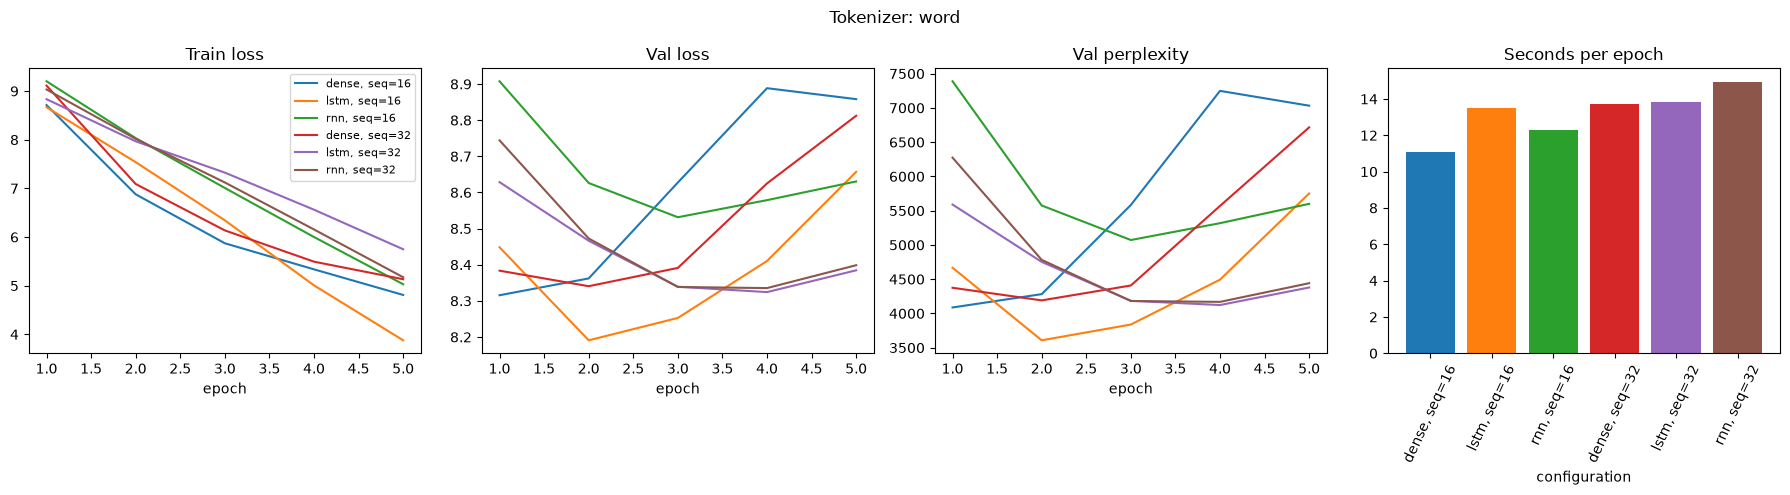

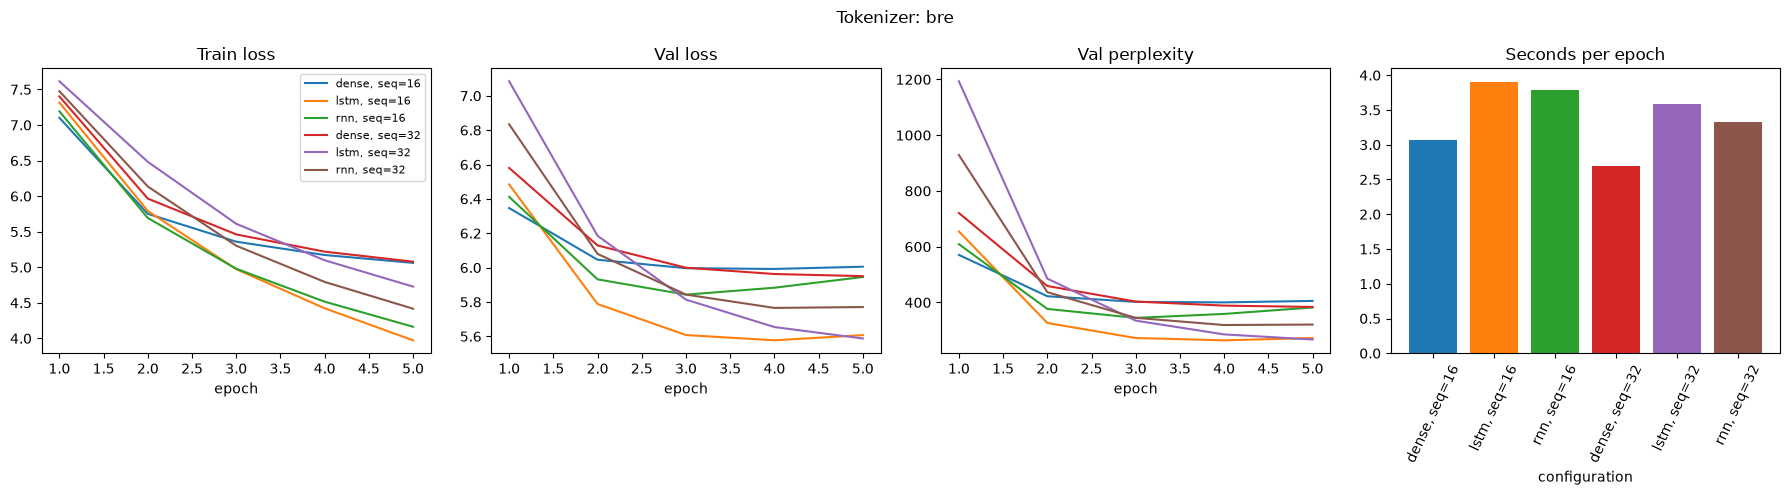

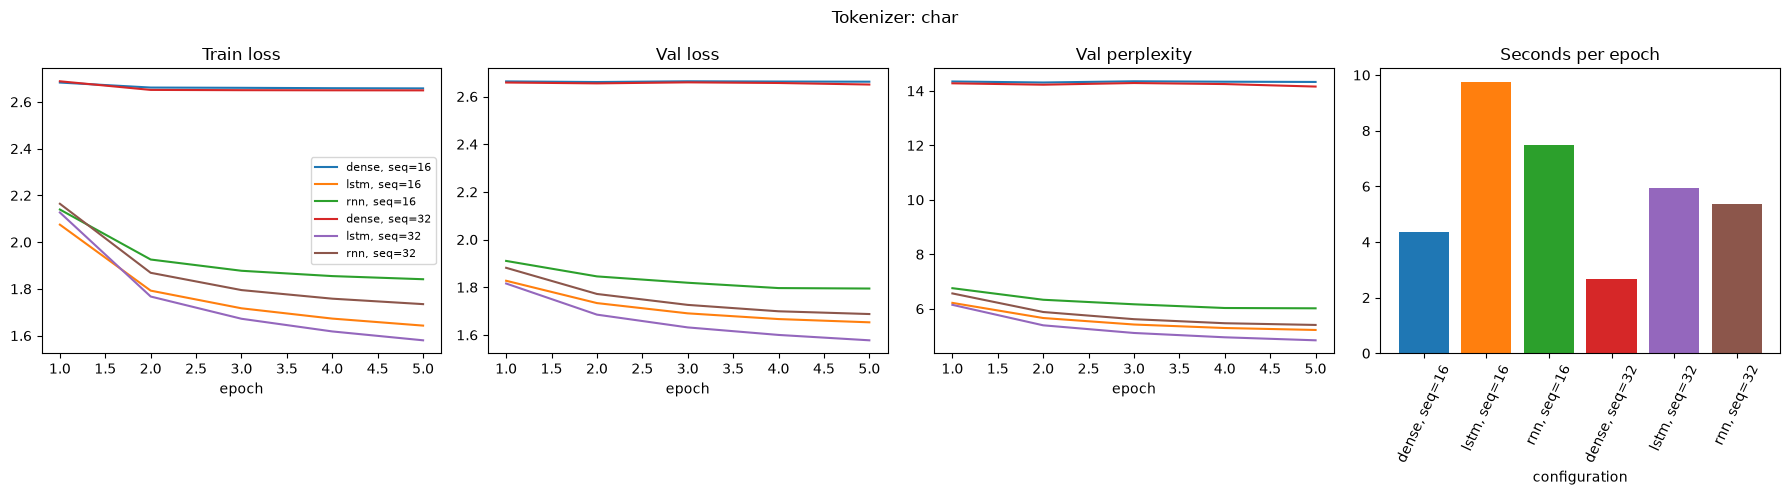

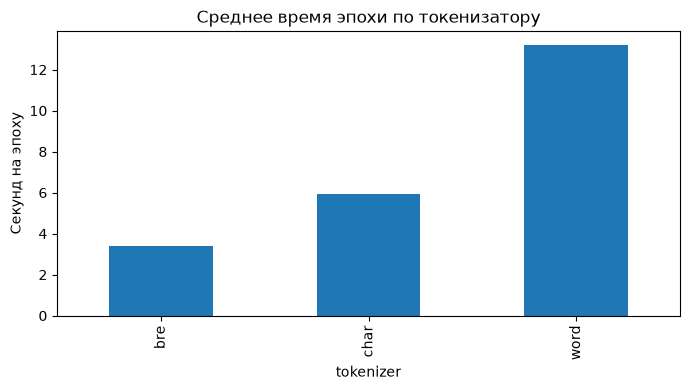

In [27]:
runs = client.search_runs([EXPERIMENT_ID], filter_string=(
    f"attributes.status = 'FINISHED' and params.stage = 'baseline' "
    f"and params.data_sha256 = '{DATA_SHA256}' and params.device = '{DEVICE}'"))
records = []
for run in runs:
    times = client.get_metric_history(run.info.run_id, "epoch_seconds")
    records.append({"run_id": run.info.run_id, "tokenizer": run.data.params["tokenizer"],
                    "architecture": run.data.params["cell_type"], "seq_len": int(run.data.params["train_seq_len"]),
                    "epochs": len(times), "test_loss": run.data.metrics["test_loss"],
                    "test_ppl": run.data.metrics["test_ppl"],
                    "seconds_per_epoch": sum(m.value for m in times) / len(times)})
summary = pd.DataFrame(records).sort_values(["tokenizer", "seq_len", "architecture"]).reset_index(drop=True)
assert len(summary) == 18 and (summary["epochs"] == 5).all()
assert not summary.duplicated(["tokenizer", "seq_len", "architecture"]).any()
assert np.isfinite(summary[["test_loss", "test_ppl", "seconds_per_epoch"]].to_numpy()).all()
summary.to_csv(CACHE_DIR / "baseline_results.csv", index=False)
display(summary.drop(columns="run_id").round(3))

for tokenizer_name in ['word', 'bre', 'char']:
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    subset = summary[summary.tokenizer == tokenizer_name]
    for row in subset.itertuples():
        label = f"{row.architecture}, seq={row.seq_len}"
        for ax, metric in zip(axes[:3], ["train_loss", "val_loss", "val_perplexity"]):
            values = client.get_metric_history(row.run_id, metric)
            ax.plot([m.step + 1 for m in values], [m.value for m in values], label=label)
        axes[3].bar(label, row.seconds_per_epoch)
    for ax, title in zip(axes, ["Train loss", "Val loss", "Val perplexity", "Seconds per epoch"]):
        ax.set_title(title)
        ax.set_xlabel("epoch" if ax is not axes[3] else "configuration")
    axes[0].legend(fontsize=8)
    axes[3].tick_params(axis="x", rotation=65)
    fig.suptitle(f"Tokenizer: {tokenizer_name}")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
summary.groupby("tokenizer")["seconds_per_epoch"].mean().plot.bar(ax=ax)
ax.set_ylabel("Секунд на эпоху")
ax.set_title("Среднее время эпохи по токенизатору")
fig.tight_layout()
plt.show()
plt.close(fig)


### Генерация текста

Во время обучения модель учится по предыдущим токенам предсказывать следующий. При генерации мы используем это умение: сначала даем модели исходный `prompt`, а затем последовательно добавляем предсказанные токены.

Например, если `prompt`:

```text
я люблю
```

модель может предсказать:

```text
читать
```

После этого получаем уже:

```text
я люблю читать
```

и модель снова должна предсказать следующий токен.

В `generate` этот процесс выполняется в цикле:

1. `prompt` преобразуется в идентификаторы токенов с помощью `tokenizer.encode()`.
2. Токены передаются в модель.
3. Модель возвращает `logits` для всех токенов словаря.
4. `torch.argmax()` выбирает токен с максимальным значением `logits`.
5. Выбранный токен добавляется к результату.
6. Новый токен снова передается в модель.

Для `RNN` и `LSTM` между шагами сохраняется `hidden`. Это скрытое состояние содержит информацию о предыдущем контексте, поэтому после первого шага достаточно передавать в модель только новый токен:

```text
prompt → модель → следующий токен
                 ↓
           hidden сохраняется
                 ↓
новый токен → модель → следующий токен
```

В `DenseLM` `hidden` не используется, поэтому модель не сохраняет контекст между отдельными шагами генерации.

Генерация продолжается максимум `max_new_tokens` раз. `torch.no_grad()` используется потому, что здесь модель не обучается, а только делает предсказания.


### Оценка генерации

После обучения модели полезно проверить не только численные метрики, но и сам результат генерации. Для текста это особенно важно: модель может иметь приемлемые значения `loss` и `perplexity`, но при этом генерировать несвязный или бессмысленный текст.

Функция `load_model` загружает из MLflow все необходимые данные для восстановления эксперимента:

* параметры модели;
* веса обученной модели;
* сохраненный токенизатор.

После загрузки модель переводится в режим `eval` и готова к генерации.

`eval_model` проверяет модель на примерах из корпуса. Для каждого текста:

1. первые `prompt_len` слов используются как исходный `prompt`;
2. следующие `generation_len` слов берутся как эталонный текст;
3. модель генерирует продолжение такой же длины;
4. сохраняются `prompt`, эталонное продолжение и результат генерации.

Получается возможность сравнить:

```
Prompt:
...

Reference:
...

Generated:
...
```

Здесь полезно оценивать результат не только по метрикам, но и глазам. При сравнении моделей можно смотреть, насколько генерация:

* похожа на связный русский текст;
* сохраняет тему исходного текста;
* продолжает мысль из `prompt`;
* содержит повторения или бессмысленные фразы;
* использует `<unk>` и другие специальные токены.
### Метрики качества генерации

Потенциально для оценки качества сгенерированного текста можно использовать специальные метрики, например BLEU, ROUGE и другие методы сравнения текстов.

Однако на данном этапе наши модели пока слишком простые и слабые, поэтому такие метрики не дадут нам особенно полезной информации. Сейчас важнее понять сам процесс генерации и научиться оценивать результат по примерам.

Более продвинутые методы оценки качества текста мы рассмотрим в следующих практических работах.


### Проверка лучшей модели

Следуем фильтру кода исходного ноутбука: выбираем лучший основной BPE-запуск (`bre`) по `test_ppl`.
Чекпоинт каждого запуска ранее выбирался по `val_loss`. Выбор по тестовой метрике здесь выполняется по шаблону;
для независимой итоговой оценки в реальном исследовании модель следовало бы выбирать по validation.
Проверяем повторную загрузку и сохранность артефактов, затем генерируем продолжение первого подходящего тестового текста.

In [28]:
best_row = summary[summary.tokenizer == "bre"].sort_values(["test_ppl", "run_id"]).iloc[0]
best = client.get_run(best_row.run_id)
print("Лучший BPE run:", best.info.run_id, best.data.params["cell_type"],
      "seq_len:", best.data.params["train_seq_len"], "test_ppl:", best.data.metrics["test_ppl"])
artifact_paths = [f"{best.info.run_name}.pt", f"{best.info.run_name}_tokenizer.pkl"]
checksums_before = {p: hashlib.sha256(Path(client.download_artifacts(best.info.run_id, p)).read_bytes()).hexdigest()
                    for p in artifact_paths}
restored_first = load_model(best.info.run_id, model_factory, DEVICE)
restored_second = load_model(best.info.run_id, model_factory, DEVICE)
assert all(torch.equal(a.cpu(), b.cpu()) for a, b in
           zip(restored_first.state_dict().values(), restored_second.state_dict().values()))
for path, checksum in checksums_before.items():
    assert hashlib.sha256(Path(client.download_artifacts(best.info.run_id, path)).read_bytes()).hexdigest() == checksum
print("Две загрузки успешны; артефакты сохранены")
del restored_first, restored_second

generation_doc = next(doc for doc in test_docs if len(doc.split()) >= 200)
generated_texts = eval_model(best.info.run_id, [generation_doc], 100, 100, model_factory, device=DEVICE)
with mlflow.start_run(run_id=best.info.run_id):
    for idx, generated_text in enumerate(generated_texts):
        result = (f"PROMPT:\n{generated_text['promt']}\n\n"
                  f"REFERENCE:\n{generated_text['reference_text']}\n\n"
                  f"GENERATED:\n{generated_text['generated_text']}")
        mlflow.log_text(result, f"generation_{idx}.txt")


Лучший BPE run: a0d5d990bc6d4f4f8768094059019f5b lstm seq_len: 16 test_ppl: 266.2643026172394


[<FileInfo: file_size=30919161, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=30919161, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


Две загрузки успешны; артефакты сохранены
[<FileInfo: file_size=30919161, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


### Просмотр результата

Мы сохранили результаты генерации в MLflow. Теперь посмотрим, какие артефакты были сохранены в выбранном запуске, и откроем один из файлов с результатом генерации.

Так мы можем вернуться к результатам эксперимента даже после завершения обучения и сравнить `PROMPT`, эталонное продолжение и текст, сгенерированный моделью.


In [29]:
artifacts = client.list_artifacts(best.info.run_id)
for artifact in artifacts:
    print(artifact.path)
text = client.download_artifacts(
    best.info.run_id,
    "generation_0.txt"
)

with open(text, encoding="utf-8") as f:
    print(f.read())

capable-auk-759.pt
capable-auk-759_tokenizer.pkl
data_manifest.json
generation_0.txt
requirements.txt


PROMPT:
Ограбление произошло в самом центре Санкт-Петербурга в доме на углу площади Тургенева и Садовой улицы. Это пятиэтажное здание дореволюционной постройки в начале XX века в нем располагался доходный дом. Сейчас там находятся магазины кафе офисы и квартиры сдаваемые внаем. А также дополнительный офис Адмиралтейский банка Советский. В четверг около 14.00 в банк ворвались вооруженные грабители в масках. Грабители разоружили охранника избили его и вместе с кассиром заперли в туалете. При этом на них надели наручники рассказал Газете.Ru источник в правоохранительных органах. В офисе в этот момент находился единственный посетитель. Его уложили на пол лицом вниз. Главной добычей преступников стало содержимое

REFERENCE:
банковских ячеек. Привезенным с собой инструментом они вскрыли около 30 ячеек в которых находились деньги и ценности клиентов. После этого разбойники скрылись на двух иномарках BMW и Subaru. Поймать грабителей по горячим следам не удалось. Офис банка был оборудован сигна

## Выводы и пояснения для защиты

`WordTokenizer` строит частотный словарь только по train. Ограничение включает три специальных токена;
неизвестные слова получают `<unk>`. `SlidingWindowDataset` хранит единый поток токенов с `<eos>` после каждой статьи.
Соседние срезы образуют вход и цель: на каждом шаге модель предсказывает следующий токен.

Dense использует только текущий токен, RNN передаёт скрытое состояние, LSTM использует состояние памяти и затворы.
При обучении состояния сбрасываются между окнами. В генерации рекуррентное состояние сохраняется между шагами.
Checkpoint выбирается по минимальному validation loss, а test используется для метрик готового checkpoint.
Perplexity равна экспоненте cross-entropy; сравнение разных токенизаторов без общей единицы нормировки некорректно.


In [30]:

for name in ["char", "word", "bre"]:
    rows = summary[summary.tokenizer == name]
    row = rows.loc[rows.test_ppl.idxmin()]
    print(f"{name}: лучшая архитектура {row.architecture}, seq_len={row.seq_len}, test_ppl={row.test_ppl:.3f}.")
print(f"Основная серия: {len(summary)} конфигураций, {summary.epochs.sum()} эпох.")
print(f"Среднее время эпохи: {summary.seconds_per_epoch.mean():.1f} с.")
print("Выбранная BPE-модель и пример её greedy-генерации приведены выше.")
print("Ограничения: 500 обучающих статей, 5 эпох и greedy decoding; повторы и несвязность ожидаемы.")
print("Результаты заданий 3–4 приведены в следующем разделе. Для переноса MLflow необходимы база и каталог артефактов из .cache.")


char: лучшая архитектура lstm, seq_len=32, test_ppl=4.831.
word: лучшая архитектура lstm, seq_len=16, test_ppl=3455.448.
bre: лучшая архитектура lstm, seq_len=16, test_ppl=266.264.
Основная серия: 18 конфигураций, 90 эпох.
Среднее время эпохи: 7.5 с.
Выбранная BPE-модель и пример её greedy-генерации приведены выше.
Ограничения: 500 обучающих статей, 5 эпох и greedy decoding; повторы и несвязность ожидаемы.
Результаты заданий 3–4 приведены в следующем разделе. Для переноса MLflow необходимы база и каталог артефактов из .cache.


### Наблюдения по выполненному эксперименту

- Внутри каждого токенизатора наименьшая `test_ppl` получена у LSTM: Char — 4,831 при окне 32, Word — 3455,448 при окне 16, BPE — 266,264 при окне 16. Эти числа относятся к разным единицам токенизации и не задают общий рейтинг токенизаторов.
- Увеличение окна с 16 до 32 не даёт одинакового выигрыша: лучшая символьная модель использует окно 32, лучшие Word/BPE-модели — окно 16. У Dense нет рекуррентной памяти, поэтому длина окна меняет организацию обучения, а не доступный контекст одного предсказания.
- У Word-моделей `train_loss` продолжает снижаться, тогда как `val_loss` после первых эпох растёт. Это признак переобучения; для теста восстановлены веса эпохи с минимальным `val_loss`.
- Время эпохи в среднем составило около 3,4 с для BPE, 5,9 с для Char и 13,2 с для Word. Стоимость зависит и от размера словаря, и от числа обучающих окон.
- В выбранном примере BPE-LSTM продолжение теряет тему ограбления и зацикливается на фразах «в том числе» и «в ближайшее время». Для 500 обучающих статей, пяти эпох и greedy decoding это ожидаемое ограничение; улучшение декодирования не входит в базовую часть.


## Самостоятельная работа

### Задание 3. Влияние объема данных

Повторите серию экспериментов, увеличив объем обучающих данных и количество эпох.

Рекомендуемые ориентиры:

* `RAW_ARTICLES_LIMIT`: возьмите как минимум в 5–10 раз больше статей, чем в базовом прогоне (например, 20000–30000 вместо 500–1000);
* `EPOCHS`: увеличьте до значения, при котором `val_loss` выходит на плато (обычно 10-20 эпох вместо 5) - ориентируйтесь на кривые, а не берите число произвольно;
* если ресурсов не хватает на полную матрицу «3 токенизатора × несколько `seq_len` × 3 архитектуры», зафиксируйте один `seq_len` (тот, что показал себя лучше в ключевом эксперименте) и варьируйте только токенизатор и архитектуру - это не считается упрощением задания, это нормальная практика при ограниченном бюджете, просто зафиксируйте выбор явно.

Важно про время: перед тем как запускать полную серию, оцените время на одном прогоне (одна эпоха, одна конфигурация) и умножьте на количество запланированных комбинаций. Если суммарное время превышает разумные рамки для вашего окружения (Colab-сессия, доступная GPU-квота и т.д.), уменьшите либо число статей, либо число эпох, либо число сравниваемых конфигураций - и опишите это решение в выводе.

Постройте три bar-графика:

* `test_ppl` для разных токенизаторов (при фиксированной архитектуре и объеме данных);
* среднее время обучения одной эпохи для разных токенизаторов;
* `test_ppl` для `Dense`, `RNN` и `LSTM` (при фиксированном токенизаторе).

На каждом графике сравните новый результат (больше данных/эпох) со значением из базового эксперимента - покажите пару столбцов «было / стало», а не только новые цифры.

**Вывод должен явно отвечать на вопросы:**

1. Как увеличение объема данных повлияло на `test_ppl` - одинаково ли для всех токенизаторов и архитектур, или есть токенизатор/архитектура, которые выигрывают больше остальных?
2. Оправдан ли прирост качества с точки зрения затраченного времени обучения ?
3. Есть ли признаки переобучения (расхождение `train_loss` и `val_loss`) при увеличении числа эпох, и как вы бы на это отреагировали (early stopping, dropout, regularization)?

### Задание 4. Сравнение генерации

Сравните генерацию текста у лучших моделей (по `test_ppl`) по трем осям:

1. разные токенизаторы (при одинаковой архитектуре и объеме данных);
2. разное количество обучающих статей ;
3. разные архитектуры внутри одного токенизатора.


```text
PROMPT:
...

REFERENCE:
...

GENERATED:
...
```

Сравните результаты визуально и сделайте вывод о том, как токенизация, архитектура и количество обучающих данных влияют на качество сгенерированного текста.

## Выполнение задания 3

Train увеличивается с 500 до 5000 статей. Validation/test (250/250) и токенизаторы сохранены из базовой серии.
Из того же снимка Gazeta загружаются первые 10 000 статей; исходные 500 train сохраняются, ещё 4500 выбираются с seed 42.
Новые дубликаты и совпадения с отложенными выборками исключаются после исходной очистки.

Фиксируем `seq_len=16`, окно лучшей базовой BPE-модели. Сравниваем девять конфигураций с девятью базовыми запусками этого окна.
Новые модели обучаются с нуля, остальные параметры сохраняются. Минимум 10, максимум 20 эпох; early stopping — три эпохи без снижения `val_loss` минимум на 0.001.
Чекпоинт всегда соответствует фактическому минимуму `val_loss`, даже если улучшение меньше порога early stopping.

Базовые результаты не переобучаются и не перезаписываются. Рост объёма данных и числа эпох исследуется совместно.

In [19]:
EXTRA_EXPERIMENT_NAME = "pz1_text_generation_extra"
if client.get_experiment_by_name(EXTRA_EXPERIMENT_NAME) is None:
    client.create_experiment(EXTRA_EXPERIMENT_NAME,
                             artifact_location=(CACHE_DIR / "mlruns" / EXTRA_EXPERIMENT_NAME).as_uri())
EXTRA_EXPERIMENT_ID = client.get_experiment_by_name(EXTRA_EXPERIMENT_NAME).experiment_id
BASE_TRAIN_DOCS = list(train_docs)
BASE_VAL_DOCS = list(val_docs)
BASE_TEST_DOCS = list(test_docs)
BASE_TRAIN_INDICES = indices[:500]
BASE_VAL_INDICES = indices[500:750]
BASE_TEST_INDICES = indices[750:]
BASE_HOLDOUT_SHA = hashlib.sha256(json.dumps([BASE_VAL_DOCS, BASE_TEST_DOCS], ensure_ascii=False).encode()).hexdigest()
baseline_summary = pd.read_csv(CACHE_DIR / "baseline_results.csv")
baseline16 = baseline_summary[baseline_summary.seq_len == 16].copy()
assert len(baseline16) == 9

RAW_ARTICLES_LIMIT_EXTRA = 10000
extra_cache = CACHE_DIR / "gazeta_first_10000.json"
if extra_cache.exists():
    extra_corpus = json.loads(extra_cache.read_text(encoding="utf-8"))
else:
    stream = load_dataset(corpus["dataset"], revision=corpus["revision"], split="train", streaming=True)
    extra_records = [{"id": str(row.get("id", i)), "text": row["text"]}
                     for i, row in enumerate(islice(stream, RAW_ARTICLES_LIMIT_EXTRA))]
    extra_corpus = {"dataset": corpus["dataset"], "revision": corpus["revision"],
                    "split": "train", "records": extra_records}
    extra_cache.write_text(json.dumps(extra_corpus, ensure_ascii=False), encoding="utf-8")
assert extra_corpus["revision"] == corpus["revision"]
assert len(extra_corpus["records"]) == RAW_ARTICLES_LIMIT_EXTRA
assert extra_corpus["records"][:1000] == corpus["records"]
raw_sha = hashlib.sha256(extra_cache.read_bytes()).hexdigest()
cleaned_extra = [clean_text(r["text"]) for r in extra_corpus["records"]]
candidates = list(range(1000, RAW_ARTICLES_LIMIT_EXTRA))
random.Random(SEED).shuffle(candidates)
seen = set(BASE_TRAIN_DOCS + BASE_VAL_DOCS + BASE_TEST_DOCS)
added_indices = []
for idx in candidates:
    doc = cleaned_extra[idx]
    if not doc or doc in seen:
        continue
    seen.add(doc)
    added_indices.append(idx)
    if len(added_indices) == 4500:
        break
assert len(added_indices) == 4500
extra_train_docs = BASE_TRAIN_DOCS + [cleaned_extra[i] for i in added_indices]
assert len(extra_train_docs) == 5000 and extra_train_docs[:500] == BASE_TRAIN_DOCS
assert not (set(extra_train_docs) & (set(BASE_VAL_DOCS) | set(BASE_TEST_DOCS)))
assert len(set(extra_train_docs[500:])) == 4500
extra_manifest = {"dataset": corpus["dataset"], "revision": corpus["revision"], "raw_sha256": raw_sha,
                  "raw_articles_limit": RAW_ARTICLES_LIMIT_EXTRA,
                  "train_indices": BASE_TRAIN_INDICES + added_indices,
                  "val_indices": BASE_VAL_INDICES, "test_indices": BASE_TEST_INDICES,
                  "holdout_sha256": BASE_HOLDOUT_SHA, "seed": SEED}
extra_manifest["sha256"] = hashlib.sha256(json.dumps(extra_manifest, sort_keys=True).encode()).hexdigest()
(CACHE_DIR / "extra_data_manifest.json").write_text(json.dumps(extra_manifest, ensure_ascii=False, indent=2))

def tokenizer_fingerprint(tokenizer):
    state = ({"type": type(tokenizer).__name__, "model": json.loads(tokenizer.tokenizer.to_str())}
             if isinstance(tokenizer, BPETokenizer)
             else {"type": type(tokenizer).__name__, "vocab": tokenizer.stoi})
    return hashlib.sha256(json.dumps(state, sort_keys=True, ensure_ascii=False).encode()).hexdigest()

EXTRA_TOKENIZERS = {}
TOKENIZER_HASHES = {}
BASE_TOKENIZER_FILES = {}
for name in ["char", "word", "bre"]:
    row = baseline16[(baseline16.tokenizer == name) & (baseline16.architecture == "lstm")].iloc[0]
    run = client.get_run(row.run_id)
    path = Path(client.download_artifacts(row.run_id, f"{run.info.run_name}_tokenizer.pkl"))
    with path.open("rb") as file:
        EXTRA_TOKENIZERS[name] = pickle.load(file)
    TOKENIZER_HASHES[name] = tokenizer_fingerprint(EXTRA_TOKENIZERS[name])
    BASE_TOKENIZER_FILES[name] = {"path": str(path), "sha256": hashlib.sha256(path.read_bytes()).hexdigest()}
assert torch.backends.mps.is_available(), "Для сопоставления времени требуется исходное устройство MPS"
DEVICE = torch.device("mps")
unk_records = []
for name, tokenizer in EXTRA_TOKENIZERS.items():
    for split, docs in [("train_500", BASE_TRAIN_DOCS), ("train_5000", extra_train_docs),
                        ("validation", BASE_VAL_DOCS), ("test", BASE_TEST_DOCS)]:
        total, unknown = 0, 0
        for doc in docs:
            ids = tokenizer.encode(doc)
            total += len(ids)
            unknown += ids.count(tokenizer.unk_id)
        unk_records.append({"tokenizer": name, "split": split, "tokens": total,
                            "unk_percent": 100 * unknown / total})
unk_summary = pd.DataFrame(unk_records)
display(unk_summary.round(3))
print("Train: 500 →", len(extra_train_docs), "; validation/test: 250/250, без изменений")
print("Исходные 35 повторных статей train сохранены; новые повторы исключены")
print("Данные:", extra_manifest["sha256"])
print("Токенизаторы:", TOKENIZER_HASHES)


,tokenizer,split,tokens,unk_percent
0,char,train_500,2020774,0.000
1,char,train_5000,20301827,0.001
2,char,validation,990733,0.001
3,char,test,1011101,0.001
4,word,train_500,303637,0.000
5,word,train_5000,3062824,11.745
6,word,validation,148498,11.560
7,word,test,151767,11.825
8,bre,train_500,495459,0.000
9,bre,train_5000,5194025,0.002


Train: 500 → 5000 ; validation/test: 250/250, без изменений
Исходные 35 повторных статей train сохранены; новые повторы исключены
Данные: 443785e3fddc504bace2da53f024e5fbb9a5a5c4282ab4b0338decab3e1787e8
Токенизаторы: {'char': '76f06c1386687fecb236905dcb5404a85d5547507523de1c27ed9668156e9933', 'word': 'b960de63590e0ce192556bceaa9be054fb97e5f30c23ec83723db6f7b31fbb7a', 'bre': '06ff1fdd15c8a53c4c099410634d4adbb50e8a2c3742fc693149c070c15cedad'}


In [20]:
from unittest.mock import MagicMock, patch
from types import SimpleNamespace
from contextlib import redirect_stdout
import io

# Проверяем minimum epochs, лимит, порог и восстановление именно лучшей эпохи.
scenarios = [([2.0, 1.5] + [1.5] * 18, 10, 2, "early_stopping"),
             ([2.0 - 0.02 * i for i in range(20)], 20, 20, "epoch_limit"),
             ([2.0, 1.5] + [1.5 - 0.0001 * (i + 1) for i in range(18)], 10, 10, "early_stopping")]
for values, expected_epochs, expected_best, expected_reason in scenarios:
    state = {"epoch": 0, "evaluation": 0}
    toy = model_factory("dense", EXTRA_TOKENIZERS["char"], 4, 4, dropout=0)
    def fake_train(model, loader, optimizer, criterion):
        state["epoch"] += 1
        with torch.no_grad():
            next(model.parameters()).fill_(state["epoch"])
        return 1.0
    def fake_evaluate(model, loader, criterion):
        idx = state["evaluation"]
        state["evaluation"] += 1
        return values[min(idx, len(values) - 1)]
    fake_mlflow = MagicMock()
    fake_run = SimpleNamespace(info=SimpleNamespace(run_id="selfcheck", run_name="early-stop-selfcheck"))
    fake_mlflow.start_run.return_value.__enter__.return_value = fake_run
    fake_mlflow.active_run.return_value = fake_run
    result_history = {}
    with patch.dict(globals(), {"mlflow": fake_mlflow, "train_one_epoch": fake_train,
                                "evaluate": fake_evaluate, "DEVICE": torch.device("cpu")}):
        with redirect_stdout(io.StringIO()):
            result_history["model"], result_history["history"] = train_model(toy, None, None, None, epochs=20, min_epochs=10,
                                 patience=3, min_delta=0.001, data_manifest=extra_manifest)
    assert len(result_history["history"]["val_loss"]) == expected_epochs
    assert float(next(result_history["model"].parameters()).flatten()[0].detach()) == expected_best
    assert fake_mlflow.log_param.call_args_list[-1].args == ("stop_reason", expected_reason)
    del toy
char = EXTRA_TOKENIZERS["char"]
toy = model_factory("dense", char, 4, 4, dropout=0)
generator = LanguageModelGenerator(toy)
assert generator.generate("Сегодня", 3) == char.decode(char.encode("Сегодня")) + generator.generate("Сегодня", 3, return_full_text=False)
del toy, generator
assert all(tokenizer_fingerprint(EXTRA_TOKENIZERS[name]) == digest for name, digest in TOKENIZER_HASHES.items())
print("Early stopping: три сценария OK; лучший checkpoint и продолжение без prompt: OK")


Early stopping: три сценария OK; лучший checkpoint и продолжение без prompt: OK


In [21]:
EXTRA_PROBE_NAME = "pz1_text_generation_extra_probe"
if client.get_experiment_by_name(EXTRA_PROBE_NAME) is None:
    client.create_experiment(EXTRA_PROBE_NAME,
                             artifact_location=(CACHE_DIR / "mlruns" / EXTRA_PROBE_NAME).as_uri())
mlflow.set_experiment(EXTRA_PROBE_NAME)
probe_loaders_extra = make_loaders(extra_train_docs, BASE_VAL_DOCS, BASE_TEST_DOCS,
                                   EXTRA_TOKENIZERS["word"], 16, batch_size=128)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
probe_model_extra = model_factory("lstm", EXTRA_TOKENIZERS["word"], 256, 512)
probe_model_extra, probe_history_extra = train_model(
    probe_model_extra, *probe_loaders_extra, epochs=1, lr=0.002,
    params={"stage": "extra_probe", "cell_type": "lstm", "tokenizer": "word", "train_seq_len": 16,
            "emb_dim": 256, "hidden_dim": 512, "num_layers": 1, "epochs": 1, "n_train": 5000,
            "batch_size": 128, "lr": 0.002, "tokenizer_sha256": TOKENIZER_HASHES["word"]},
    data_manifest=extra_manifest)
probe_seconds_extra = client.get_metric_history(probe_history_extra["run_id"], "epoch_seconds")[0].value
print(f"Word-LSTM, одна эпоха на train 5000: {probe_seconds_extra:.1f} с.")
print(f"Условная оценка для 9 × 20 эпох с такой же стоимостью: {180 * probe_seconds_extra / 3600:.2f} ч.")
print("Это не верхняя граница: скорость зависит от конфигурации; early stopping может сократить число эпох.")
del probe_model_extra, probe_loaders_extra
mlflow.set_experiment(EXTRA_EXPERIMENT_NAME)
gc.collect(); torch.mps.empty_cache()


[capable-auk-759] epoch 1/1 
params: {'stage': 'extra_probe', 'cell_type': 'lstm', 'tokenizer': 'word', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 1, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'tokenizer_sha256': 'b960de63590e0ce192556bceaa9be054fb97e5f30c23ec83723db6f7b31fbb7a'} 
train_loss=6.431 val_loss=5.968 val_ppl=390.6 
lr=2.00e-03, seconds=103.9


Word-LSTM, одна эпоха на train 5000: 103.9 с.
Условная оценка для 9 × 20 эпох с такой же стоимостью: 5.19 ч.
Это не верхняя граница: скорость зависит от конфигурации; early stopping может сократить число эпох.


In [22]:
mlflow.set_experiment(EXTRA_EXPERIMENT_NAME)
for tokenizer_name in ["bre", "char", "word"]:
    tokenizer = EXTRA_TOKENIZERS[tokenizer_name]
    assert tokenizer_fingerprint(tokenizer) == TOKENIZER_HASHES[tokenizer_name]
    loaders_extra = make_loaders(extra_train_docs, BASE_VAL_DOCS, BASE_TEST_DOCS,
                                  tokenizer, 16, batch_size=128)
    for cell_type in ["dense", "rnn", "lstm"]:
        params_extra = {"stage": "expanded", "cell_type": cell_type, "tokenizer": tokenizer_name,
                        "train_seq_len": 16, "emb_dim": 256, "hidden_dim": 512, "num_layers": 1,
                        "epochs": 20, "n_train": 5000, "batch_size": 128, "lr": 0.002,
                        "dropout": 0.2, "tokenizer_sha256": TOKENIZER_HASHES[tokenizer_name]}
        filters = ["attributes.status = 'FINISHED'", f"params.data_sha256 = '{extra_manifest['sha256']}'",
                   f"params.device = '{DEVICE}'", f"params.seed = '{SEED}'",
                   "params.min_epochs = '10'", "params.patience = '3'", "params.min_delta = '0.001'"]
        filters += [f"params.{key} = '{value}'" for key, value in params_extra.items()]
        finished = client.search_runs([EXTRA_EXPERIMENT_ID], filter_string=" and ".join(filters))
        if finished:
            print("Сохранённый расширенный запуск:", tokenizer_name, cell_type, finished[0].info.run_id, flush=True)
            continue
        random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
        model_extra = model_factory(cell_type, tokenizer, 256, 512, num_layers=1, dropout=0.2)
        print("Расширенное обучение:", tokenizer_name, cell_type, flush=True)
        model_extra, history_extra = train_model(
            model_extra, *loaders_extra, epochs=20, lr=0.002, params=params_extra,
            min_epochs=10, patience=3, min_delta=0.001, data_manifest=extra_manifest)
        del model_extra, history_extra
        gc.collect(); torch.mps.empty_cache()
    del loaders_extra


Расширенное обучение: bre dense


[capable-auk-759] epoch 1/20 
params: {'stage': 'expanded', 'cell_type': 'dense', 'tokenizer': 'bre', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': '06ff1fdd15c8a53c4c099410634d4adbb50e8a2c3742fc693149c070c15cedad'} 
train_loss=5.831 val_loss=5.548 val_ppl=256.8 
lr=2.00e-03, seconds=27.8


[capable-auk-759] epoch 2/20 
params: {'stage': 'expanded', 'cell_type': 'dense', 'tokenizer': 'bre', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': '06ff1fdd15c8a53c4c099410634d4adbb50e8a2c3742fc693149c070c15cedad'} 
train_loss=5.461 val_loss=5.485 val_ppl=241.0 
lr=2.00e-03, seconds=34.7


[capable-auk-759] epoch 3/20 
params: {'stage': 'expanded', 'cell_type': 'dense', 'tokenizer': 'bre', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': '06ff1fdd15c8a53c4c099410634d4adbb50e8a2c3742fc693149c070c15cedad'} 
train_loss=5.395 val_loss=5.459 val_ppl=235.0 
lr=2.00e-03, seconds=38.8


[capable-auk-759] epoch 4/20 
params: {'stage': 'expanded', 'cell_type': 'dense', 'tokenizer': 'bre', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': '06ff1fdd15c8a53c4c099410634d4adbb50e8a2c3742fc693149c070c15cedad'} 
train_loss=5.356 val_loss=5.437 val_ppl=229.7 
lr=2.00e-03, seconds=38.8


...

[capable-auk-759] epoch 7/20 
params: {'stage': 'expanded', 'cell_type': 'lstm', 'tokenizer': 'word', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': 'b960de63590e0ce192556bceaa9be054fb97e5f30c23ec83723db6f7b31fbb7a'} 
train_loss=3.938 val_loss=5.887 val_ppl=360.3 
lr=1.00e-03, seconds=113.2


[capable-auk-759] epoch 8/20 
params: {'stage': 'expanded', 'cell_type': 'lstm', 'tokenizer': 'word', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': 'b960de63590e0ce192556bceaa9be054fb97e5f30c23ec83723db6f7b31fbb7a'} 
train_loss=3.795 val_loss=5.946 val_ppl=382.2 
lr=1.00e-03, seconds=114.2


[capable-auk-759] epoch 9/20 
params: {'stage': 'expanded', 'cell_type': 'lstm', 'tokenizer': 'word', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': 'b960de63590e0ce192556bceaa9be054fb97e5f30c23ec83723db6f7b31fbb7a'} 
train_loss=3.692 val_loss=6.001 val_ppl=404.0 
lr=5.00e-04, seconds=114.0


[capable-auk-759] epoch 10/20 
params: {'stage': 'expanded', 'cell_type': 'lstm', 'tokenizer': 'word', 'train_seq_len': 16, 'emb_dim': 256, 'hidden_dim': 512, 'num_layers': 1, 'epochs': 20, 'n_train': 5000, 'batch_size': 128, 'lr': 0.002, 'dropout': 0.2, 'tokenizer_sha256': 'b960de63590e0ce192556bceaa9be054fb97e5f30c23ec83723db6f7b31fbb7a'} 
train_loss=3.496 val_loss=6.043 val_ppl=421.3 
lr=5.00e-04, seconds=113.9


Early stopping: epoch=10, stale=7


### Сравнение «было / стало»

На всех графиках окно равно 16. «Было» — train 500 и 5 эпох; «стало» — train 5000 и фактическое число эпох.
Perplexity сравнивается между режимами внутри одного токенизатора; численные значения разных токенизаторов нельзя считать общей шкалой качества.
Среднее время эпохи включает обучение и validation, затем усредняется по Dense/RNN/LSTM.

,tokenizer,architecture,test_ppl_base,test_ppl_extra,ppl_change_percent,epochs_extra,best_epoch,seconds_per_epoch_base,seconds_per_epoch_extra,stop_reason
0,bre,dense,401.646,210.093,-47.692,20,19,3.064,34.042,epoch_limit
1,bre,lstm,266.264,99.774,-62.528,10,7,3.904,42.188,early_stopping
2,bre,rnn,348.043,146.618,-57.874,11,8,3.782,37.406,early_stopping
3,char,dense,14.261,13.941,-2.245,12,9,4.362,33.058,early_stopping
4,char,lstm,5.209,4.471,-14.182,20,19,9.753,89.700,epoch_limit
5,char,rnn,5.994,5.876,-1.959,10,1,7.477,58.545,early_stopping
6,word,dense,3916.757,415.690,-89.387,13,10,11.082,113.961,early_stopping
7,word,lstm,3455.448,276.031,-92.012,10,3,13.478,114.637,early_stopping
8,word,rnn,4843.597,390.816,-91.931,10,2,12.310,116.904,early_stopping


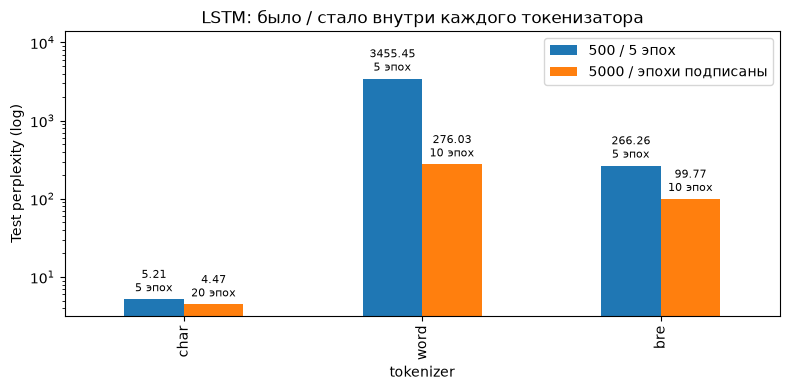

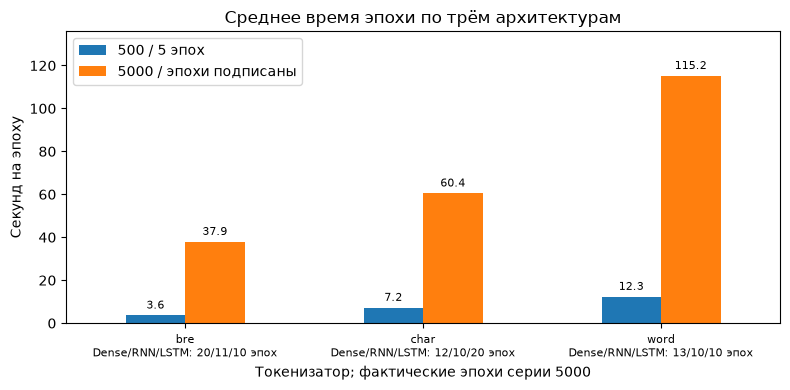

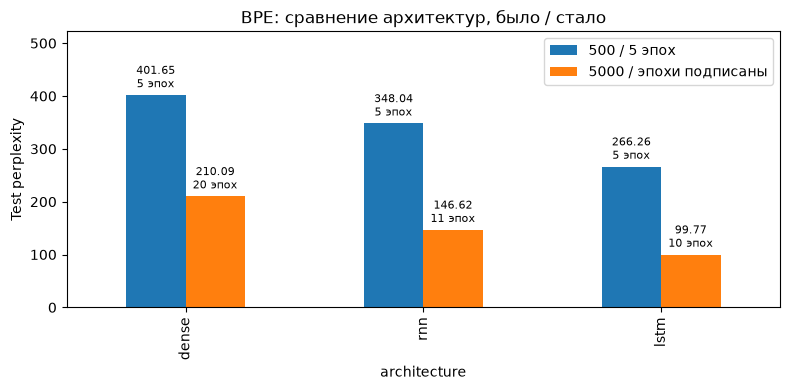

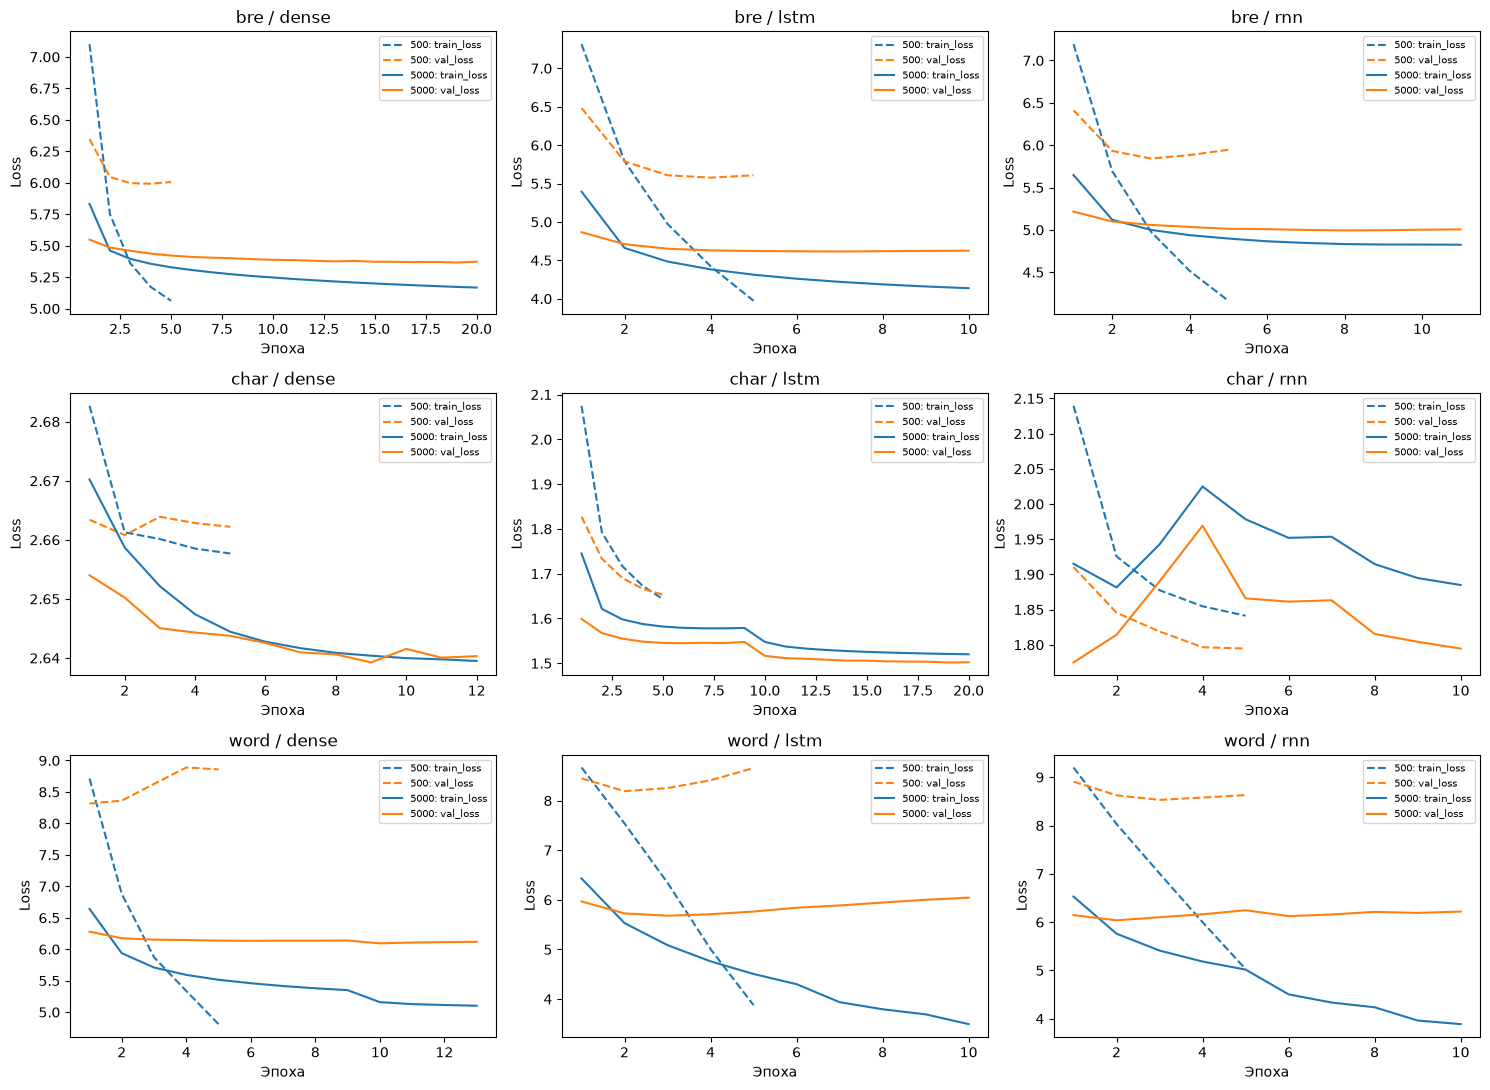

In [21]:
expanded_runs = client.search_runs([EXTRA_EXPERIMENT_ID], filter_string=(
    f"attributes.status = 'FINISHED' and params.stage = 'expanded' "
    f"and params.data_sha256 = '{extra_manifest['sha256']}'"))
extra_rows = []
for run in expanded_runs:
    epoch_times = client.get_metric_history(run.info.run_id, "epoch_seconds")
    extra_rows.append({"run_id": run.info.run_id, "tokenizer": run.data.params["tokenizer"],
                       "architecture": run.data.params["cell_type"], "seq_len": 16,
                       "epochs": len(epoch_times), "test_loss": run.data.metrics["test_loss"],
                       "test_ppl": run.data.metrics["test_ppl"],
                       "seconds_per_epoch": sum(m.value for m in epoch_times) / len(epoch_times),
                       "training_seconds": run.data.metrics["training_seconds"],
                       "best_epoch": int(run.data.metrics["best_epoch"]),
                       "stop_reason": run.data.params["stop_reason"]})
expanded_summary = pd.DataFrame(extra_rows).sort_values(["tokenizer", "architecture"]).reset_index(drop=True)
assert len(expanded_summary) == 9
assert not expanded_summary.duplicated(["tokenizer", "architecture"]).any()
assert expanded_summary.epochs.between(10, 20).all()
assert np.isfinite(expanded_summary[["test_loss", "test_ppl", "seconds_per_epoch"]].to_numpy()).all()
comparison = baseline16.merge(expanded_summary, on=["tokenizer", "architecture", "seq_len"], suffixes=("_base", "_extra"))
comparison["ppl_change_percent"] = 100 * (comparison.test_ppl_extra / comparison.test_ppl_base - 1)
expanded_summary.to_csv(CACHE_DIR / "expanded_results.csv", index=False)
comparison.to_csv(CACHE_DIR / "extra_comparison.csv", index=False)
display(comparison[["tokenizer", "architecture", "test_ppl_base", "test_ppl_extra", "ppl_change_percent",
                    "epochs_extra", "best_epoch", "seconds_per_epoch_base", "seconds_per_epoch_extra", "stop_reason"]].round(3))

figure_files = []
fig, ax = plt.subplots(figsize=(8, 4))
lstm_comparison = comparison[comparison.architecture == "lstm"].set_index("tokenizer").loc[["char", "word", "bre"]]
lstm_comparison[["test_ppl_base", "test_ppl_extra"]].rename(columns={"test_ppl_base": "500 / 5 эпох", "test_ppl_extra": "5000 / эпохи подписаны"}).plot.bar(ax=ax)
for container, epochs in zip(ax.containers, [[5] * 3, lstm_comparison.epochs_extra]):
    ax.bar_label(container, labels=[f"{bar.get_height():.2f}\n{int(count)} эпох"
                                  for bar, count in zip(container, epochs)], fontsize=8, padding=3)
ax.set_yscale("log"); ax.set_ylabel("Test perplexity (log)")
ax.set_ylim(top=lstm_comparison.test_ppl_base.max() * 4)
ax.set_title("LSTM: было / стало внутри каждого токенизатора")
fig.tight_layout(); fig.savefig(CACHE_DIR / "extra_ppl_tokenizers.png", dpi=150)
figure_files.append(CACHE_DIR / "extra_ppl_tokenizers.png")
plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4))
timing = comparison.groupby("tokenizer")[["seconds_per_epoch_base", "seconds_per_epoch_extra"]].mean()
timing.rename(columns={"seconds_per_epoch_base": "500 / 5 эпох", "seconds_per_epoch_extra": "5000 / эпохи подписаны"}).plot.bar(ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", fontsize=8, padding=3)
labels = []
for name in timing.index:
    counts = expanded_summary[expanded_summary.tokenizer == name].set_index("architecture").loc[["dense", "rnn", "lstm"], "epochs"]
    labels.append(f"{name}\nDense/RNN/LSTM: {'/'.join(str(int(v)) for v in counts)} эпох")
ax.set_xticklabels(labels, rotation=0, fontsize=8)
ax.set_ylim(top=timing.seconds_per_epoch_extra.max() * 1.18)
ax.set_ylabel("Секунд на эпоху"); ax.set_xlabel("Токенизатор; фактические эпохи серии 5000")
ax.set_title("Среднее время эпохи по трём архитектурам")
fig.tight_layout(); fig.savefig(CACHE_DIR / "extra_epoch_times.png", dpi=150)
figure_files.append(CACHE_DIR / "extra_epoch_times.png")
plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4))
bpe_comparison = comparison[comparison.tokenizer == "bre"].set_index("architecture").loc[["dense", "rnn", "lstm"]]
bpe_comparison[["test_ppl_base", "test_ppl_extra"]].rename(columns={"test_ppl_base": "500 / 5 эпох", "test_ppl_extra": "5000 / эпохи подписаны"}).plot.bar(ax=ax)
for container, epochs in zip(ax.containers, [[5] * 3, bpe_comparison.epochs_extra]):
    ax.bar_label(container, labels=[f"{bar.get_height():.2f}\n{int(count)} эпох"
                                  for bar, count in zip(container, epochs)], fontsize=8, padding=3)
ax.set_ylim(top=bpe_comparison.test_ppl_base.max() * 1.3)
ax.set_ylabel("Test perplexity"); ax.set_title("BPE: сравнение архитектур, было / стало")
fig.tight_layout(); fig.savefig(CACHE_DIR / "extra_ppl_architectures.png", dpi=150)
figure_files.append(CACHE_DIR / "extra_ppl_architectures.png")
plt.show(); plt.close(fig)

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for row, ax in zip(comparison.itertuples(), axes.flat):
    for run_id, prefix, style in [(row.run_id_base, "500", "--"), (row.run_id_extra, "5000", "-")]:
        for metric, color in [("train_loss", "tab:blue"), ("val_loss", "tab:orange")]:
            values = client.get_metric_history(run_id, metric)
            ax.plot([m.step + 1 for m in values], [m.value for m in values], style,
                    color=color, label=f"{prefix}: {metric}")
    ax.set_title(f"{row.tokenizer} / {row.architecture}"); ax.set_xlabel("Эпоха"); ax.set_ylabel("Loss")
    ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(CACHE_DIR / "extra_loss_curves.png", dpi=150)
figure_files.append(CACHE_DIR / "extra_loss_curves.png")
plt.show(); plt.close(fig)


In [22]:
print("Изменение test_ppl внутри каждого токенизатора:")
for row in comparison.itertuples():
    print(f"{row.tokenizer}/{row.architecture}: {row.test_ppl_base:.2f} → {row.test_ppl_extra:.2f} "
          f"({row.ppl_change_percent:+.1f}%), эпох={row.epochs_extra}, лучшая={row.best_epoch}, {row.stop_reason}")
print(f"Дополнительное обучение: {expanded_summary.training_seconds.sum() / 3600:.2f} ч, "
      f"{expanded_summary.epochs.sum()} эпох.")
print("Изменение нельзя приписать только объёму данных: одновременно увеличено число эпох.")
for row in expanded_summary.itertuples():
    train_curve = client.get_metric_history(row.run_id, "train_loss")
    val_curve = client.get_metric_history(row.run_id, "val_loss")
    last_gap = val_curve[-1].value - train_curve[-1].value
    print(f"{row.tokenizer}/{row.architecture}: разрыв val−train на последней эпохе {last_gap:.3f}; "
          f"validation minimum на эпохе {row.best_epoch} из {row.epochs}.")
limited = expanded_summary[expanded_summary.stop_reason == "epoch_limit"]
print("Лимит 20 эпох без срабатывания early stopping:",
      [(r.tokenizer, r.architecture) for r in limited.itertuples()])
print("Для переобучения: early stopping уже включён; дальнейшие меры — больший dropout или регуляризация.")


Изменение test_ppl внутри каждого токенизатора:
bre/dense: 401.65 → 210.09 (-47.7%), эпох=20, лучшая=19, epoch_limit
bre/lstm: 266.26 → 99.77 (-62.5%), эпох=10, лучшая=7, early_stopping
bre/rnn: 348.04 → 146.62 (-57.9%), эпох=11, лучшая=8, early_stopping
char/dense: 14.26 → 13.94 (-2.2%), эпох=12, лучшая=9, early_stopping
char/lstm: 5.21 → 4.47 (-14.2%), эпох=20, лучшая=19, epoch_limit
char/rnn: 5.99 → 5.88 (-2.0%), эпох=10, лучшая=1, early_stopping
word/dense: 3916.76 → 415.69 (-89.4%), эпох=13, лучшая=10, early_stopping
word/lstm: 3455.45 → 276.03 (-92.0%), эпох=10, лучшая=3, early_stopping
word/rnn: 4843.60 → 390.82 (-91.9%), эпох=10, лучшая=2, early_stopping
Дополнительное обучение: 2.25 ч, 116 эпох.
Изменение нельзя приписать только объёму данных: одновременно увеличено число эпох.
bre/dense: разрыв val−train на последней эпохе 0.205; validation minimum на эпохе 19 из 20.
bre/lstm: разрыв val−train на последней эпохе 0.488; validation minimum на эпохе 7 из 10.
bre/rnn: разрыв val−

## Выполнение задания 4

Берём первые три документа исходного test длиной минимум 200 слов. Для всех моделей одинаковы 100 слов prompt и следующие 100 слов reference.
Число новых токенов равно длине reference в токенах конкретного токенизатора. Используется greedy decoding без изменения стратегии.
В `GENERATED` показано только продолжение, без повторного вывода prompt.

Сравниваем токенизаторы при LSTM и train 5000; объёмы 500/5000 при LSTM для каждого токенизатора;
архитектуры Dense/RNN/LSTM при BPE и train 5000. Это 8 различных моделей и 24 продолжения; общие модели вычисляются один раз.
Чекпоинты выбраны по validation. `test_ppl` показана для сопоставления моделей внутри одного токенизатора.

In [23]:
generation_docs_extra = [doc for doc in BASE_TEST_DOCS if len(doc.split()) >= 200][:3]
assert len(generation_docs_extra) == 3
fixed_examples = [{"prompt": " ".join(doc.split()[:100]),
                   "reference": " ".join(doc.split()[100:200])} for doc in generation_docs_extra]
selected_models = []
for regime, table in [("500", baseline16), ("5000", expanded_summary)]:
    for row in table[table.architecture == "lstm"].itertuples():
        selected_models.append((regime, row.tokenizer, row.architecture, row.run_id, row.test_ppl))
for row in expanded_summary[(expanded_summary.tokenizer == "bre") & (expanded_summary.architecture != "lstm")].itertuples():
    selected_models.append(("5000", row.tokenizer, row.architecture, row.run_id, row.test_ppl))
assert len(selected_models) == 8
all_generations = []
for regime, name, architecture, run_id, ppl in selected_models:
    restored = load_model(run_id, model_factory, DEVICE)
    assert tokenizer_fingerprint(restored.tokenizer) == TOKENIZER_HASHES[name]
    generator = LanguageModelGenerator(restored)
    for idx, example in enumerate(fixed_examples):
        count = restored.tokenizer.get_token_count(example["reference"])
        text = generator.generate(example["prompt"], max_new_tokens=count, return_full_text=False)
        all_generations.append({"regime": regime, "tokenizer": name, "architecture": architecture,
                                "run_id": run_id, "test_ppl": float(ppl), "example": idx,
                                "prompt": example["prompt"], "reference": example["reference"],
                                "new_tokens": count, "generated": text})
    del restored, generator
    gc.collect(); torch.mps.empty_cache()
assert len(all_generations) == 24
for record in all_generations:
    assert record["prompt"] == fixed_examples[record["example"]]["prompt"]
    assert record["reference"] == fixed_examples[record["example"]]["reference"]
(CACHE_DIR / "extra_generations.json").write_text(json.dumps(all_generations, ensure_ascii=False, indent=2))
axes_generation = [("Разные токенизаторы, LSTM, train 5000", lambda r: r["regime"] == "5000" and r["architecture"] == "lstm"),
                   ("Объём данных, LSTM, каждый токенизатор", lambda r: r["architecture"] == "lstm"),
                   ("Архитектуры, BPE, train 5000", lambda r: r["regime"] == "5000" and r["tokenizer"] == "bre")]
for title, predicate in axes_generation:
    print("\n" + "=" * 70 + "\n" + title)
    for record in filter(predicate, all_generations):
        print(f"\n{record['tokenizer']} / {record['architecture']} / train {record['regime']} / "
              f"test_ppl={record['test_ppl']:.3f} / пример {record['example'] + 1}")
        print("PROMPT:\n" + record["prompt"] + "\n\nREFERENCE:\n" + record["reference"] +
              "\n\nGENERATED:\n" + record["generated"])

# Общие материалы относятся к расширенной серии; базовые запуски остаются неизменными.
report_run_id = expanded_summary[(expanded_summary.tokenizer == "bre") & (expanded_summary.architecture == "lstm")].iloc[0].run_id
for path in [CACHE_DIR / "extra_generations.json", CACHE_DIR / "extra_comparison.csv",
             CACHE_DIR / "extra_data_manifest.json", *figure_files]:
    client.log_artifact(report_run_id, str(path))


[<FileInfo: file_size=30919161, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=5474, is_dir=False, path='generation_0.txt'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=6766393, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=1672, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=157050489, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=1525861, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=9135, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=30919161, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=54352, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=2475, is_dir=False, path='extra_comparison.csv'>, <FileInfo: file_size=54352, is_dir=False, path='extra_data_manifest.json'>, <FileInfo: file_size=31013, is_dir=False, path='extra_epoch_times.png'>, <FileInfo: file_size=97614, is_dir=False, path='extra_generations.json'>, <FileInfo: file_size=304428, is_dir=False, path='extra_loss_curves.png'>, <FileInfo: file_size=32938, is_dir=False, path='extra_ppl_architectures.png'>, <FileInfo: file_size=31646, is_dir=False, path='extra_ppl_tokenizers.png'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=6766393, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=1672, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=54352, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=157050489, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=1525861, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=54352, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=25137073, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=54352, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]


[<FileInfo: file_size=26188281, is_dir=False, path='capable-auk-759.pt'>, <FileInfo: file_size=728908, is_dir=False, path='capable-auk-759_tokenizer.pkl'>, <FileInfo: file_size=54352, is_dir=False, path='data_manifest.json'>, <FileInfo: file_size=299, is_dir=False, path='requirements.txt'>]



Разные токенизаторы, LSTM, train 5000

bre / lstm / train 5000 / test_ppl=99.774 / пример 1
PROMPT:
Ограбление произошло в самом центре Санкт-Петербурга в доме на углу площади Тургенева и Садовой улицы. Это пятиэтажное здание дореволюционной постройки в начале XX века в нем располагался доходный дом. Сейчас там находятся магазины кафе офисы и квартиры сдаваемые внаем. А также дополнительный офис Адмиралтейский банка Советский. В четверг около 14.00 в банк ворвались вооруженные грабители в масках. Грабители разоружили охранника избили его и вместе с кассиром заперли в туалете. При этом на них надели наручники рассказал Газете.Ru источник в правоохранительных органах. В офисе в этот момент находился единственный посетитель. Его уложили на пол лицом вниз. Главной добычей преступников стало содержимое

REFERENCE:
банковских ячеек. Привезенным с собой инструментом они вскрыли около 30 ячеек в которых находились деньги и ценности клиентов. После этого разбойники скрылись на двух иномарках B

## Выводы по заданию 3: объём данных

Расширенная серия заняла **2,25 часа обучения: 116 эпох для 9 моделей**, дополнительно выполнена отдельная пробная эпоха Word-LSTM (103,9 с). Проба не использовалась как начальные веса. Все модели обучены с нуля на MPS. Время эпохи включает обучение и validation; это измерение текущего компьютера, а не универсальная характеристика архитектуры.

Самое сильное относительное снижение `test_ppl` наблюдается у Word: Dense **3916,76 → 415,69 (−89,4%)**, RNN **4843,60 → 390,82 (−91,9%)**, LSTM **3455,45 → 276,03 (−92,0%)**. Но Word-словарь заморожен: в train 500 неизвестных токенов не было, в train 5000 их **11,745%**, а в test — **11,825%**. Поэтому часть выигрыша может быть связана с обучением вероятности общего `<unk>`, а не с освоением новой лексики. Отдельный вклад этого эффекта не измерялся. Генерация ниже показывает, почему одной метрики недостаточно.

Для BPE улучшились все архитектуры: Dense **401,65 → 210,09 (−47,7%)**, RNN **348,04 → 146,62 (−57,9%)**, LSTM **266,26 → 99,77 (−62,5%)**. При BPE LSTM остаётся лучшей из трёх архитектур. У Char эффект меньше: Dense **−2,2%**, RNN **−2,0%**, LSTM **−14,2%**. Это сравнение изменений внутри каждого токенизатора; абсолютные perplexity Char/Word/BPE имеют разные единицы предсказания и напрямую не ранжируются.

Дополнительное время оправдано для проверки влияния корпуса и снижения ошибки BPE-LSTM: её серия заняла около **7,1 минуты** при 10 эпохах. Для Char-Dense и Char-RNN выигрыш около 2% при существенно большем времени выглядит слабым. Средняя эпоха по трём архитектурам: BPE **37,9 с**, Char **60,4 с**, Word **115,2 с**. Снижение perplexity не обеспечило связного продолжения на 100 слов: при таком критерии качества затраты пока себя не оправдали.

Переобучение наиболее заметно у Word-RNN и Word-LSTM: минимумы validation на эпохах **2 и 3**, затем train loss продолжает падать, а validation растёт. У Word-LSTM train loss снизился с **5,087** на третьей эпохе до **3,496** на десятой, тогда как val loss вырос с **5,681 до 6,043**. Чекпоинт взят с третьей эпохи. У BPE-LSTM после минимума на седьмой эпохе есть небольшой рост validation при снижении train loss; BPE-RNN достигает минимума на восьмой эпохе. Минимум 10 эпох из плана ограничивает раннюю остановку Word-моделей, но не выбор лучшего чекпоинта.

У Char-RNN минимум validation достигнут на первой эпохе, затем ухудшаются обе кривые. Это указывает также на нестабильность оптимизации; сводить эффект только к переобучению нельзя. У Char-LSTM нет растущего разрыва validation относительно train; снижение learning rate после девятой эпохи дало новое улучшение. Train loss считается с dropout и меняющимися весами в течение эпохи, validation — без dropout по весам в конце, поэтому небольшой отрицательный разрыв допустим.

**BPE-Dense и Char-LSTM дошли до лимита 20 эпох без срабатывания early stopping. Выход на плато для них не подтверждён.** Остальные семь запусков остановлены по правилу patience. Сохранялся фактический минимум validation даже при улучшении менее 0,001. Возможные меры против переобучения: более ранняя остановка при снятии минимума 10 эпох, увеличение dropout, регуляризация весов. Эти дополнительные эксперименты здесь не проводились.

Исходные 500 train-документов включены в 5000 без изменения, включая 35 повторных записей исходной train-выборки. Добавленные 4500 документов уникальны после очистки. Validation/test и все три токенизатора сохранены. **Одновременно увеличены корпус и число эпох; их самостоятельный вклад этим экспериментом не измеряется.** При одинаковом `seq_len=16` контекст в словах также различается между токенизаторами.

## Выводы по заданию 4: генерация

Использованы три первых подходящих test-документа: об ограблении банка, приговоре юристу и процессе по делу Квачкова. Для каждого во всех сравнениях совпадают 100 слов prompt и следующие 100 слов reference. Получены **24 уникальные генерации: 8 моделей × 3 документа**; повторяющиеся модели используют те же сохранённые результаты. Длина продолжения задана числом токенов соответствующего reference, поэтому число напечатанных слов может отличаться от 100. Чекпоинты выбраны по validation, `test_ppl` показана рядом с каждым примером.

**Токенизаторы при LSTM и train 5000.** Char выдаёт узнаваемые слова, но быстро повторяет «представитель» во всех трёх примерах; тема prompt теряется. Word во всех примерах генерирует только `<unk>`: 111, 109 и 106 токенов соответственно. BPE лучше сохраняет общую судебно-криминальную лексику: «в ходе следствия», «о возбуждении уголовного дела». Но конкретные обстоятельства ограбления, приговора и процесса не продолжаются; одна общая конструкция циклически повторяется. Локальные фразы связнее, чем весь текст.

**Train 500 против 5000, LSTM.** Char меняет цикл «продолжает продолжают продажи» на повтор одного слова; улучшение perplexity не стало улучшением связности greedy-текста. Word на 500 статьях печатает однотипные фразы «в итоге в россии», а на 5000 полностью переходит к `<unk>`: полезность генерации ухудшилась при снижении perplexity. Это согласуется с высокой частотой `<unk>` в расширенной обучающей выборке и выбором самого вероятного токена. BPE на 500 статьях зацикливается на «странице тенниса» и сообщении ГИБДД; на 5000 чаще использует лексику расследования, но повторы сохраняются. Увеличение корпуса улучшило соответствие общему жанру для BPE, но не фактическую точность продолжения.

**Архитектуры при BPE и train 5000.** Dense почти сразу повторяет «В итоге в Москве». RNN в первом примере начинает со слова «имущество», затем повторяет «В качестве примера»; во втором и третьем уходит к хоккейной лексике, не связанной с исходными судебными текстами. LSTM с `test_ppl=99,77` лучше удерживает общую тему расследования, чем Dense (210,09) и RNN (146,62), но тоже зацикливается. Даже лучшая метрика не гарантирует смыслового продолжения исходной новости.

В декодированном выводе `<pad>` и `<eos>` не встречаются; `<unk>` явно виден у расширенной Word-LSTM. Для BPE вывод декодера сам по себе не доказывает отсутствие специальных идентификаторов, поскольку декодер может их скрывать. Специальные токены не маскировались, greedy decoding сохранён. Три примера дают качественное наблюдение, а не статистическое доказательство превосходства модели по связности.

## Проверка готовности

Проверены вложенность train 500 в train 5000, неизменность validation/test, отсутствие пересечения очищенных текстов и совпадение контрольных сумм токенизаторов. Три коротких сценария проверяют minimum epochs, patience, лимит и сохранение истинного минимума validation. Все **9 дополнительных запусков завершены**, значения метрик конечны. Все девять чекпоинтов восстановлены; повторная оценка на test воспроизвела сохранённый loss с допуском 2·10⁻⁶.

Контрольные суммы артефактов, метрики и статусы всех **18 базовых запусков** совпали со снимком до расширения. Исходный ноутбук преподавателя сохранён. Итоговый `.ipynb` содержит выполненные ячейки, графики и тексты без ошибок выполнения. Коммит и отправка в Moodle не выполнялись.
